# Hafta 9 — GPT Tokenizer'ı sıfırdan: Byte Pair Encoding (BPE)

Geçen hafta karakter seviyesinde bir tokenizer kullandık: her karakter bir token. Bunun iki bedeli var:

1. **Vocab, metni nasıl temizlediğimize bağlı.** Aynı Türkçe metinden teslimlere göre 89 ile 353 arasında farklı karakter çıktı.
2. **Diziler uzun.** Model her harf için bir adım atıyor, bu yüzden `block_size`'ın içine çok az metin sığıyor.

Bu hafta harf yerine **sık geçen harf gruplarını** tek token yapıyoruz. Bunu yapan algoritma Byte Pair Encoding (BPE) ve GPT-2, GPT-4 gibi modellerin tokenizer'ı da bu.

**Akış:** Her görevde önce Karpathy'nin videosundaki İngilizce örnekle algoritmayı kuruyoruz, sonra aynı şeyi geçen haftaki Türkçe metinde (Ömer Seyfettin hikâyeleri) yapıyoruz.

| Görev | Konu | Video |
|---|---|---|
| 1 | Unicode, UTF-8: bir harf kaç byte? | 0:14:56 – 0:23:50 |
| 2 | BPE'yi sıfırdan yazıp Türkçe metinde eğitmek | 0:23:50 – 0:39:20 |
| 3 | encode / decode | 0:42:47 – 0:57:36 |
| 4 | GPT-4'ün regex deseni | 0:57:36 – 1:11:38 |
| 5 | Türkçe ve İngilizce: kaç token? | |

# **1- Metni byte'lara çevir. Türkçe harfler içeren bir cümle seç (ç, ğ, ı, ö, ş, ü). Her harfin Unicode kod noktasını ve UTF-8 byte'larını yazdır. Hangi harfler 1 byte, hangileri 2 byte tutuyor? Kod noktalarını doğrudan vocab olarak kullanmak neden kötü bir fikir, kendi cümlelerinle yaz. (0:14:56 - 0:23:50)**

# Tokenization :(

Tokenization is at the heart of much weirdness of LLMs. Do not brush it off.

- Why can't LLM spell words? **Tokenization**.
- Why can't LLM do super simple string processing tasks like reversing a string? **Tokenization**.
- Why is LLM worse at non-English languages (e.g. Japanese)? **Tokenization**.
- Why is LLM bad at simple arithmetic? **Tokenization**.
- Why did GPT-2 have more than necessary trouble coding in Python? **Tokenization**.
- Why did my LLM abruptly halt when it sees the string "<|endoftext|>"? **Tokenization**.
- What is this weird warning I get about a "trailing whitespace"? **Tokenization**.
- Why the LLM break if I ask it about "SolidGoldMagikarp"? **Tokenization**.
- Why should I prefer to use YAML over JSON with LLMs? **Tokenization**.
- Why is LLM not actually end-to-end language modeling? **Tokenization**.
- What is the real root of suffering? **Tokenization**.

---

Good tokenization web app: [https://tiktokenizer.vercel.app](https://tiktokenizer.vercel.app)

Example string:

```
Tokenization is at the heart of much weirdness of LLMs. Do not brush it off.

127 + 677 = 804
1275 + 6773 = 8041

Egg.
I have an Egg.
egg.
EGG.

만나서 반가워요. 저는 OpenAI에서 개발한 대규모 언어 모델인 ChatGPT입니다. 궁금한 것이 있으시면 무엇이든 물어보세요.

for i in range(1, 101):
    if i % 3 == 0 and i % 5 == 0:
        print("FizzBuzz")
    elif i % 3 == 0:
        print("Fizz")
    elif i % 5 == 0:
        print("Buzz")
    else:
        print(i)
```

---

Much glory awaits someone who can delete the need for tokenization. But meanwhile, let's learn about it.


Karpathy videoya bu listeyle başlıyor: LLM'lerin "tuhaf" hatalarının çoğu modelden değil tokenizer'dan geliyor. Birkaçının kısa açıklaması:

- **Heceleme ve harf sayma:** Model kelimeyi harf harf değil token token görüyor. `" strawberry"` birkaç token, içindeki `r`'leri ayrı ayrı göremiyor.
- **Aritmetik:** Sayılar keyfi parçalara bölünüyor (`1275` bir token, `6773` iki token olabilir). Model basamakları hizalı göremiyor.
- **İngilizce dışındaki diller:** Tokenizer İngilizce ağırlıklı veride eğitildiği için diğer dillerde aynı metin daha fazla token tutuyor. Dizi uzuyor, bağlam penceresi daralıyor. Görev 5'te bunu Türkçe için ölçüyoruz.
- **Python kodu:** GPT-2 girintideki her boşluğu ayrı token yapıyordu, kod dizileri gereksiz uzuyordu. GPT-4 boşlukları birleştiriyor.

In [1]:
"안녕하세요 👋 (hello in Korean!)"

'안녕하세요 👋 (hello in Korean!)'

In [2]:
ord("h") # karakterlerin unicode code'unu veriyor

104

In [3]:
[ord(x)for x in "안녕하세요 👋 (hello in Korean!)"]

[50504,
 45397,
 54616,
 49464,
 50836,
 32,
 128075,
 32,
 40,
 104,
 101,
 108,
 108,
 111,
 32,
 105,
 110,
 32,
 75,
 111,
 114,
 101,
 97,
 110,
 33,
 41]

In [4]:
list("안녕하세요 👋 (hello in Korean!)".encode("utf-8"))

[236,
 149,
 136,
 235,
 133,
 149,
 237,
 149,
 152,
 236,
 132,
 184,
 236,
 154,
 148,
 32,
 240,
 159,
 145,
 139,
 32,
 40,
 104,
 101,
 108,
 108,
 111,
 32,
 105,
 110,
 32,
 75,
 111,
 114,
 101,
 97,
 110,
 33,
 41]

### Çıktıları okumak

- `ord()` bir karakterin **Unicode kod noktasını** veriyor: `ord("h") = 104`. Unicode, dünyadaki karakterlerin her birine sabit bir numara veren standart.
- Korece cümle 26 karakter, yani 26 kod noktası. Ama `.encode("utf-8")` **39 byte** döndürdü. Fark şuradan geliyor:
  - ASCII karakterler (`h`, `e`, boşluk, parantez) 1 byte: 20 karakter → 20 byte
  - Her Korece hece 3 byte (`안` → `236, 149, 136`): 5 hece → 15 byte
  - `👋` 4 byte (`240, 159, 145, 139`)
  - 20 + 15 + 4 = **39**
- Byte'ların hepsi 0–255 arasında. Byte'larla çalışırsak vocab tam **256** ile başlıyor ve hiç değişmiyor. BPE bu 256'nın üstüne inşa edilecek.

### Unicode ve UTF-8

**Kod noktası ve kodlama farklı şeyler.** Unicode her karaktere bir numara veriyor (`ş` → 351). Ama bilgisayar bu numarayı diske ya da belleğe **byte** olarak yazmak zorunda. Numarayı byte'lara çeviren kurala **kodlama** (encoding) deniyor. Üç tane var: UTF-8, UTF-16, UTF-32.

- **UTF-32** her karakteri 4 byte'la yazıyor. İngilizce metinde byte'ların çoğu `0`, çok israf.
- **UTF-16** 2 ya da 4 byte. İngilizcede yine her harfin yarısı `0`.
- **UTF-8** 1 ile 4 byte arası, değişken uzunluklu. İnternetin standardı. Karpathy de bunu seçiyor.

**UTF-8'in kuralı:**

| Kod noktası aralığı | Byte | Bit deseni | Örnek |
|---|---|---|---|
| 0 – 127 (ASCII) | 1 | `0xxxxxxx` | `a`, `A`, `5`, boşluk |
| 128 – 2.047 | 2 | `110xxxxx 10xxxxxx` | `ç ğ ı ö ş ü İ` |
| 2.048 – 65.535 | 3 | `1110xxxx 10xxxxxx 10xxxxxx` | `€`, Korece heceler |
| 65.536 ve üstü | 4 | `11110xxx 10xxxxxx ×3` | `👋` |

İlk byte'ın başındaki bitler "bu karakter kaç byte" bilgisini taşıyor. `10` ile başlayan byte'lar **devam byte'ı**: tek başlarına bir anlamları yok, önlerinde bir başlangıç byte'ı olmak zorunda. Bu bilgi Görev 3'te decode'da işimize yarayacak.

**Türkçe harfler neden 2 byte?** UTF-8 eski ASCII ile uyumlu olsun diye ilk 128 numara tek byte'a ayrıldı ve oraya yalnızca İngilizce alfabe sığdı. `ç ö ü` Latin-1 Supplement bloğunda (U+00C0–U+00FF), `ğ ı ş İ` Latin Extended-A bloğunda (U+0100–U+017F). İkisi de 127'nin üstünde ama 2.048'in altında, yani 2 byte'lık aralıkta. Örneğin `ç` (231) = `11000011 10100111`: ilk byte'taki `110` "2 byte'lık karakter", ikincideki `10` "devam byte'ı" demek. Her Türkçe harfte 16 bitin 5'i bu işaretlere gidiyor.

### Kod noktalarını doğrudan vocab olarak kullanmak neden kötü bir fikir?

1. **Vocab çok büyük olur.** Unicode'da yaklaşık 150.000 karakter var. Embedding tablosu ve çıkış katmanı 150 bin satıra çıkar ve bu satırların çoğu eğitim verisinde neredeyse hiç geçmeyen karakterlere ait olur, yani hiç öğrenilmez.
2. **Standart sabit değil.** Unicode'a her yıl yeni karakterler (özellikle emoji) ekleniyor. Vocab'ı buna bağlarsak sabit bir temsilimiz olmaz.
3. **Dizi yine kısalmaz.** Kod noktası kullanmak hâlâ "her karakter bir token" demek. `block_size` sorunu olduğu gibi duruyor.

**Ham byte'lar da tek başına yetmiyor.** Byte kullanırsak ilk iki sorun çözülüyor: vocab tam 256 ve hiç değişmiyor. Ama üçüncüsü kötüleşiyor: Türkçe harflerin her biri iki adım tutuyor, dizi karakter seviyesinden de uzun oluyor. Karpathy burada tokenizer'ı tamamen kaldırmayı da konuşuyor (MegaByte makalesi, ham byte üzerinde çalışan hiyerarşik transformer), ama bu henüz büyük ölçekte kanıtlanmış bir yöntem değil.

**Çözüm:** byte'larla başla, sık geçen byte ikililerini birleştirerek diziyi kısalt. Bu BPE.

> **Geçen haftayla bağlantı:** `ö` iki biçimde yazılabiliyor: tek kod noktası (U+00F6, 2 byte) ya da `o` + birleştirici iki nokta (U+0308, toplam 3 byte). Ekranda aynı görünüyorlar ama ikincisi `set(text)`'te iki ayrı karakter sayılıyor. Python'da `"İ".lower()` de tek harf değil, `i` + U+0307 (birleştirici nokta). 89 ile 353 arasındaki farkın bir kısmı buradan geliyor. `unicodedata.normalize("NFC", text)` görünüşü aynı olan karakterleri tek biçime getiriyor.

Şimdi aynısını Türkçe bir cümleyle yapalım. Cümle olarak Türkçe pangramı seçtim: *"Pijamalı hasta yağız şoföre çabucak güvendi."* Bu cümlede alfabedeki 29 harfin hepsi var, yani ç, ğ, ı, ö, ş, ü'nün hepsini tek cümlede görebiliyoruz.

In [5]:
cumle = "Pijamalı hasta yağız şoföre çabucak güvendi." # Türkçe pangram, 29 harfin hepsi var
print(cumle)
print("karakter sayısı:", len(cumle))
print("byte sayısı:", len(cumle.encode("utf-8"))) # karakterden fazla çıkıyor çünkü Türkçe harfler 2 byte

Pijamalı hasta yağız şoföre çabucak güvendi.
karakter sayısı: 44
byte sayısı: 51


In [6]:
# her farklı karakterin kod noktasını ve utf-8 byte'larını yazdırıyoruz. dict.fromkeys sırayı koruyarak tekrarları atıyor
for ch in dict.fromkeys(cumle):
    b = list(ch.encode("utf-8"))
    print(f"{ch!r:6} kod noktası: U+{ord(ch):04X} ({ord(ch):3})   utf-8: {str(b):11} {len(b)} byte")

'P'    kod noktası: U+0050 ( 80)   utf-8: [80]        1 byte
'i'    kod noktası: U+0069 (105)   utf-8: [105]       1 byte
'j'    kod noktası: U+006A (106)   utf-8: [106]       1 byte
'a'    kod noktası: U+0061 ( 97)   utf-8: [97]        1 byte
'm'    kod noktası: U+006D (109)   utf-8: [109]       1 byte
'l'    kod noktası: U+006C (108)   utf-8: [108]       1 byte
'ı'    kod noktası: U+0131 (305)   utf-8: [196, 177]  2 byte
' '    kod noktası: U+0020 ( 32)   utf-8: [32]        1 byte
'h'    kod noktası: U+0068 (104)   utf-8: [104]       1 byte
's'    kod noktası: U+0073 (115)   utf-8: [115]       1 byte
't'    kod noktası: U+0074 (116)   utf-8: [116]       1 byte
'y'    kod noktası: U+0079 (121)   utf-8: [121]       1 byte
'ğ'    kod noktası: U+011F (287)   utf-8: [196, 159]  2 byte
'z'    kod noktası: U+007A (122)   utf-8: [122]       1 byte
'ş'    kod noktası: U+015F (351)   utf-8: [197, 159]  2 byte
'o'    kod noktası: U+006F (111)   utf-8: [111]       1 byte
'f'    kod noktası: U+00

In [7]:
bir_byte = sorted(set(ch for ch in cumle if len(ch.encode("utf-8")) == 1))
iki_byte = sorted(set(ch for ch in cumle if len(ch.encode("utf-8")) == 2))
print("1 byte:", bir_byte)
print("2 byte:", iki_byte)
print("ç'nin bitleri:", [f"{b:08b}" for b in "ç".encode("utf-8")]) # 110xxxxx 10xxxxxx deseni

1 byte: [' ', '.', 'P', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'r', 's', 't', 'u', 'v', 'y', 'z']
2 byte: ['ç', 'ö', 'ü', 'ğ', 'ı', 'ş']
ç'nin bitleri: ['11000011', '10100111']


Gördüğünüz gibi İngilizce alfabede de olan harflerin hepsi, boşluk ve nokta 1 byte. ç, ö, ü, ğ, ı, ş ise 2 byte. Cümle 44 karakter ama 51 byte tutuyor: cümlede 7 tane Türkçe harf var (ı iki kere geçiyor) ve her biri 1 byte fazladan getiriyor.

ç'nin bitlerine bakınca UTF-8'in kuralı görünüyor: `11000011 10100111`. İlk byte `110` ile başlıyor, bu "ben 2 byte'lık bir karakterin başıyım" demek. İkinci byte `10` ile başlıyor, bu da "ben devam byte'ıyım" demek. Geriye kalan bitleri yan yana koyunca (`00011` + `100111`) 231 çıkıyor, yani ç'nin kod noktası.

In [8]:
# geçen haftaki karakter sayısı farkının bir sebebi: aynı görünen harfin iki farklı yazılışı
import unicodedata
o1 = "ö"                               # tek kod noktası
o2 = unicodedata.normalize("NFD", "ö") # o + birleştirici iki nokta
print(o1, o2, o1 == o2, len(o1), len(o2), list(o1.encode("utf-8")), list(o2.encode("utf-8")))
print(len("İ".lower()), [f"U+{ord(c):04X}" for c in "İ".lower()]) # İ küçültülünce i + birleştirici nokta oluyor

ö ö False 1 2 [195, 182] [111, 204, 136]
2 ['U+0069', 'U+0307']


ö'yü iki farklı şekilde yazdık. Ekranda ikisi de aynı görünüyor ama Python'a göre eşit değiller. Birincisi tek kod noktası ve 2 byte. İkincisi o + birleştirici iki nokta, yani 2 kod noktası ve 3 byte. İ'yi küçültünce de tek harf değil iki kod noktası çıkıyor: i ve U+0307.

Geçen hafta vocab'ın teslimlere göre 89'dan 353'e kadar değişmesinin bir sebebi bu olabilir. `set(text)` bu iki ö'yü farklı karakterler olarak sayıyor. `unicodedata.normalize("NFC", text)` bunları tek bir biçime getiriyor.

# **2- BPE'yi sıfırdan yaz ve kendi Türkçe metninde eğit. Geçen hafta derlediğin Türkçe metni kullan. Ardışık ikilileri say, en sık geçeni yeni bir token'la birleştir, istediğin vocab boyutuna gelene kadar tekrarla. İlk 20 birleştirmeyi metin olarak yazdır: hangi harf grupları önce birleşiyor? Sıkıştırma oranını (byte sayısı / token sayısı) yaz. (0:23:50 - 0:39:20)**

Wikipedia örneği:
  - aaabdaaabac → aa=Z → ZabdZabac → ab=Y → ZYdZYac → ZY=X → XdXac
  - Dizi 11'den 5'e indi, vocab 4'ten 7'ye çıktı.
  - Fikrin tamamı bu: dizi uzunluğuyla vocab boyutu arasında bir alışveriş yapıyorsun.

**Algoritma, adım adım:**

1. Metni UTF-8 byte'larına çevir. Başlangıç vocab'ı 256 (0–255).
2. Ardışık tüm ikilileri say.
3. En sık geçen ikiliye yeni bir id ver (256, 257, …) ve metinde o ikilinin geçtiği her yeri bu id ile değiştir.
4. İstediğin vocab boyutuna gelene kadar 2–3'ü tekrarla.

Her birleştirmede vocab bir büyüyor, dizi o ikilinin geçme sayısı kadar kısalıyor. **Vocab boyutu bir hiperparametre:** büyük vocab daha kısa dizi demek, ama embedding tablosu büyüyor ve her token eğitimde daha seyrek görülüyor. GPT-2'de yaklaşık 50 bin, GPT-4'te yaklaşık 100 bin.

In [9]:
# text from https://www.reedbeta.com/blog/programmers-intro-to-unicode/
text = "Ｕｎｉｃｏｄｅ! 🅤🅝🅘🅒🅞🅓🅔‽ 🇺‌🇳‌🇮‌🇨‌🇴‌🇩‌🇪! 😄 The very name strikes fear and awe into the hearts of programmers worldwide. We all know we ought to “support Unicode” in our software (whatever that means—like using wchar_t for all the strings, right?). But Unicode can be abstruse, and diving into the thousand-page Unicode Standard plus its dozens of supplementary annexes, reports, and notes can be more than a little intimidating. I don’t blame programmers for still finding the whole thing mysterious, even 30 years after Unicode’s inception."
tokens = text.encode("utf-8") # raw bytes
tokens = list(map(int, tokens)) # convert to a list of integers in range 0..255 for convenience
print('---')
print(text)
print("length:", len(text))
print('---')
print(tokens)
print("length:", len(tokens))

---
Ｕｎｉｃｏｄｅ! 🅤🅝🅘🅒🅞🅓🅔‽ 🇺‌🇳‌🇮‌🇨‌🇴‌🇩‌🇪! 😄 The very name strikes fear and awe into the hearts of programmers worldwide. We all know we ought to “support Unicode” in our software (whatever that means—like using wchar_t for all the strings, right?). But Unicode can be abstruse, and diving into the thousand-page Unicode Standard plus its dozens of supplementary annexes, reports, and notes can be more than a little intimidating. I don’t blame programmers for still finding the whole thing mysterious, even 30 years after Unicode’s inception.
length: 533
---
[239, 188, 181, 239, 189, 142, 239, 189, 137, 239, 189, 131, 239, 189, 143, 239, 189, 132, 239, 189, 133, 33, 32, 240, 159, 133, 164, 240, 159, 133, 157, 240, 159, 133, 152, 240, 159, 133, 146, 240, 159, 133, 158, 240, 159, 133, 147, 240, 159, 133, 148, 226, 128, 189, 32, 240, 159, 135, 186, 226, 128, 140, 240, 159, 135, 179, 226, 128, 140, 240, 159, 135, 174, 226, 128, 140, 240, 159, 135, 168, 226, 128, 140, 240, 159, 135, 180, 226, 128, 140

Karpathy'nin metni: Nathan Reed'in "A Programmer's Introduction to Unicode" yazısının ilk paragrafı. **533 karakter → 616 byte.** Byte sayısının karakter sayısından fazla olması baştaki süslü karakterlerden (`Ｕ` 3 byte, `🅤` 4 byte) ve tipografik işaretlerden (`’ “ ” —` 3'er byte) geliyor.

`list(map(int, tokens))` byte nesnesini 0–255 arası tamsayıların listesine çeviriyor. Artık elimizde bir sayı dizisi var ve BPE bu dizi üzerinde çalışacak.

In [10]:
def get_stats(ids):
    counts = {}
    for pair in zip(ids, ids[1:]): # Pythonic way to iterate consecutive elements
        counts[pair] = counts.get(pair, 0) + 1
    return counts

stats = get_stats(tokens)
# print(stats)
# print(sorted(((v,k) for k,v in stats.items()), reverse=True))

In [11]:
top_pair = max(stats, key=stats.get)
top_pair

(101, 32)

**`get_stats`:** `zip(ids, ids[1:])` listeyi bir kaydırılmış haliyle yan yana koyuyor: `[a, b, c, d]` → `(a,b), (b,c), (c,d)`. Yani her ardışık ikiliyi bir kez geziyoruz. Sözlük her ikilinin kaç kez geçtiğini tutuyor: `counts.get(pair, 0) + 1`, ikili ilk kez görülüyorsa 0'dan başlıyor.

**`max(stats, key=stats.get)`:** Sözlüğün anahtarları üzerinde dolaşıyor ama karşılaştırmayı değerlere (sayılara) göre yapıyor. Sonuç en sık geçen ikili.

**Sonuç `(101, 32)`:** `chr(101) = 'e'`, `chr(32) = ' '`. İngilizcede en sık ikili "kelime sonundaki e + boşluk" (*the, are, one, name…*). Karpathy'nin paragrafında 20 kez geçiyor.

In [12]:
def merge(ids, pair, idx):
  # in the list of ints (ids), replace all consecutive occurences of pair with the new token idx
  newids = []
  i = 0
  while i < len(ids):
    # if we are not at the very last position AND the pair matches, replace it
    if i < len(ids) - 1 and ids[i] == pair[0] and ids[i+1] == pair[1]:
      newids.append(idx)
      i += 2
    else:
      newids.append(ids[i])
      i += 1
  return newids

print(merge([5, 6, 6, 7, 9, 1], (6, 7), 99))

tokens2 = merge(tokens, top_pair, 256)
print(tokens2)
print("length:", len(tokens2))

[5, 6, 99, 9, 1]
[239, 188, 181, 239, 189, 142, 239, 189, 137, 239, 189, 131, 239, 189, 143, 239, 189, 132, 239, 189, 133, 33, 32, 240, 159, 133, 164, 240, 159, 133, 157, 240, 159, 133, 152, 240, 159, 133, 146, 240, 159, 133, 158, 240, 159, 133, 147, 240, 159, 133, 148, 226, 128, 189, 32, 240, 159, 135, 186, 226, 128, 140, 240, 159, 135, 179, 226, 128, 140, 240, 159, 135, 174, 226, 128, 140, 240, 159, 135, 168, 226, 128, 140, 240, 159, 135, 180, 226, 128, 140, 240, 159, 135, 169, 226, 128, 140, 240, 159, 135, 170, 33, 32, 240, 159, 152, 132, 32, 84, 104, 256, 118, 101, 114, 121, 32, 110, 97, 109, 256, 115, 116, 114, 105, 107, 101, 115, 32, 102, 101, 97, 114, 32, 97, 110, 100, 32, 97, 119, 256, 105, 110, 116, 111, 32, 116, 104, 256, 104, 101, 97, 114, 116, 115, 32, 111, 102, 32, 112, 114, 111, 103, 114, 97, 109, 109, 101, 114, 115, 32, 119, 111, 114, 108, 100, 119, 105, 100, 101, 46, 32, 87, 256, 97, 108, 108, 32, 107, 110, 111, 119, 32, 119, 256, 111, 117, 103, 104, 116, 32, 116, 111, 

**`merge` nasıl çalışıyor:**

- Listeyi soldan sağa geziyor. `i` konumundaki ikili aranan ikiliyse yeni listeye yeni id'yi (`idx`) yazıyor ve **2 adım** atlıyor, çünkü iki elemanı birden tüketti. Değilse elemanı olduğu gibi kopyalayıp 1 adım ilerliyor.
- `i < len(ids) - 1` kontrolü son eleman için: orada `ids[i+1]` yok, kontrol olmasa liste dışına taşardık.
- Oyuncak örnek: `[5, 6, 6, 7, 9, 1]` içinde `(6, 7)` → `99` ⇒ `[5, 6, 99, 9, 1]`. İlk `6`'nın yanında `6` var, eşleşmiyor ve kopyalanıyor. İkinci `6` ile `7` birleşiyor.

**Gerçek metinde:** `(101, 32)` → `256`. Dizi **616'dan 596'ya** indi: 20 tane `"e "` vardı, her biri iki elemanı bire indirdi. Çıktıda 256'ları görebilirsiniz: `84, 104, 256` = `T`, `h`, `"e "`.

In [13]:
# making the training text longer to have more representative token statistics
# text from https://www.reedbeta.com/blog/programmers-intro-to-unicode/
text = """A Programmer’s Introduction to Unicode March 3, 2017 · Coding · 22 Comments  Ｕｎｉｃｏｄｅ! 🅤🅝🅘🅒🅞🅓🅔‽ 🇺\u200c🇳\u200c🇮\u200c🇨\u200c🇴\u200c🇩\u200c🇪! 😄 The very name strikes fear and awe into the hearts of programmers worldwide. We all know we ought to “support Unicode” in our software (whatever that means—like using wchar_t for all the strings, right?). But Unicode can be abstruse, and diving into the thousand-page Unicode Standard plus its dozens of supplementary annexes, reports, and notes can be more than a little intimidating. I don’t blame programmers for still finding the whole thing mysterious, even 30 years after Unicode’s inception.  A few months ago, I got interested in Unicode and decided to spend some time learning more about it in detail. In this article, I’ll give an introduction to it from a programmer’s point of view.  I’m going to focus on the character set and what’s involved in working with strings and files of Unicode text. However, in this article I’m not going to talk about fonts, text layout/shaping/rendering, or localization in detail—those are separate issues, beyond my scope (and knowledge) here.  Diversity and Inherent Complexity The Unicode Codespace Codespace Allocation Scripts Usage Frequency Encodings UTF-8 UTF-16 Combining Marks Canonical Equivalence Normalization Forms Grapheme Clusters And More… Diversity and Inherent Complexity As soon as you start to study Unicode, it becomes clear that it represents a large jump in complexity over character sets like ASCII that you may be more familiar with. It’s not just that Unicode contains a much larger number of characters, although that’s part of it. Unicode also has a great deal of internal structure, features, and special cases, making it much more than what one might expect a mere “character set” to be. We’ll see some of that later in this article.  When confronting all this complexity, especially as an engineer, it’s hard not to find oneself asking, “Why do we need all this? Is this really necessary? Couldn’t it be simplified?”  However, Unicode aims to faithfully represent the entire world’s writing systems. The Unicode Consortium’s stated goal is “enabling people around the world to use computers in any language”. And as you might imagine, the diversity of written languages is immense! To date, Unicode supports 135 different scripts, covering some 1100 languages, and there’s still a long tail of over 100 unsupported scripts, both modern and historical, which people are still working to add.  Given this enormous diversity, it’s inevitable that representing it is a complicated project. Unicode embraces that diversity, and accepts the complexity inherent in its mission to include all human writing systems. It doesn’t make a lot of trade-offs in the name of simplification, and it makes exceptions to its own rules where necessary to further its mission.  Moreover, Unicode is committed not just to supporting texts in any single language, but also to letting multiple languages coexist within one text—which introduces even more complexity.  Most programming languages have libraries available to handle the gory low-level details of text manipulation, but as a programmer, you’ll still need to know about certain Unicode features in order to know when and how to apply them. It may take some time to wrap your head around it all, but don’t be discouraged—think about the billions of people for whom your software will be more accessible through supporting text in their language. Embrace the complexity!  The Unicode Codespace Let’s start with some general orientation. The basic elements of Unicode—its “characters”, although that term isn’t quite right—are called code points. Code points are identified by number, customarily written in hexadecimal with the prefix “U+”, such as U+0041 “A” latin capital letter a or U+03B8 “θ” greek small letter theta. Each code point also has a short name, and quite a few other properties, specified in the Unicode Character Database.  The set of all possible code points is called the codespace. The Unicode codespace consists of 1,114,112 code points. However, only 128,237 of them—about 12% of the codespace—are actually assigned, to date. There’s plenty of room for growth! Unicode also reserves an additional 137,468 code points as “private use” areas, which have no standardized meaning and are available for individual applications to define for their own purposes.  Codespace Allocation To get a feel for how the codespace is laid out, it’s helpful to visualize it. Below is a map of the entire codespace, with one pixel per code point. It’s arranged in tiles for visual coherence; each small square is 16×16 = 256 code points, and each large square is a “plane” of 65,536 code points. There are 17 planes altogether.  Map of the Unicode codespace (click to zoom)  White represents unassigned space. Blue is assigned code points, green is private-use areas, and the small red area is surrogates (more about those later). As you can see, the assigned code points are distributed somewhat sparsely, but concentrated in the first three planes.  Plane 0 is also known as the “Basic Multilingual Plane”, or BMP. The BMP contains essentially all the characters needed for modern text in any script, including Latin, Cyrillic, Greek, Han (Chinese), Japanese, Korean, Arabic, Hebrew, Devanagari (Indian), and many more.  (In the past, the codespace was just the BMP and no more—Unicode was originally conceived as a straightforward 16-bit encoding, with only 65,536 code points. It was expanded to its current size in 1996. However, the vast majority of code points in modern text belong to the BMP.)  Plane 1 contains historical scripts, such as Sumerian cuneiform and Egyptian hieroglyphs, as well as emoji and various other symbols. Plane 2 contains a large block of less-common and historical Han characters. The remaining planes are empty, except for a small number of rarely-used formatting characters in Plane 14; planes 15–16 are reserved entirely for private use.  Scripts Let’s zoom in on the first three planes, since that’s where the action is:  Map of scripts in Unicode planes 0–2 (click to zoom)  This map color-codes the 135 different scripts in Unicode. You can see how Han () and Korean () take up most of the range of the BMP (the left large square). By contrast, all of the European, Middle Eastern, and South Asian scripts fit into the first row of the BMP in this diagram.  Many areas of the codespace are adapted or copied from earlier encodings. For example, the first 128 code points of Unicode are just a copy of ASCII. This has clear benefits for compatibility—it’s easy to losslessly convert texts from smaller encodings into Unicode (and the other direction too, as long as no characters outside the smaller encoding are used).  Usage Frequency One more interesting way to visualize the codespace is to look at the distribution of usage—in other words, how often each code point is actually used in real-world texts. Below is a heat map of planes 0–2 based on a large sample of text from Wikipedia and Twitter (all languages). Frequency increases from black (never seen) through red and yellow to white.  Heat map of code point usage frequency in Unicode planes 0–2 (click to zoom)  You can see that the vast majority of this text sample lies in the BMP, with only scattered usage of code points from planes 1–2. The biggest exception is emoji, which show up here as the several bright squares in the bottom row of plane 1.  Encodings We’ve seen that Unicode code points are abstractly identified by their index in the codespace, ranging from U+0000 to U+10FFFF. But how do code points get represented as bytes, in memory or in a file?  The most convenient, computer-friendliest (and programmer-friendliest) thing to do would be to just store the code point index as a 32-bit integer. This works, but it consumes 4 bytes per code point, which is sort of a lot. Using 32-bit ints for Unicode will cost you a bunch of extra storage, memory, and performance in bandwidth-bound scenarios, if you work with a lot of text.  Consequently, there are several more-compact encodings for Unicode. The 32-bit integer encoding is officially called UTF-32 (UTF = “Unicode Transformation Format”), but it’s rarely used for storage. At most, it comes up sometimes as a temporary internal representation, for examining or operating on the code points in a string.  Much more commonly, you’ll see Unicode text encoded as either UTF-8 or UTF-16. These are both variable-length encodings, made up of 8-bit or 16-bit units, respectively. In these schemes, code points with smaller index values take up fewer bytes, which saves a lot of memory for typical texts. The trade-off is that processing UTF-8/16 texts is more programmatically involved, and likely slower.  UTF-8 In UTF-8, each code point is stored using 1 to 4 bytes, based on its index value.  UTF-8 uses a system of binary prefixes, in which the high bits of each byte mark whether it’s a single byte, the beginning of a multi-byte sequence, or a continuation byte; the remaining bits, concatenated, give the code point index. This table shows how it works:  UTF-8 (binary)\tCode point (binary)\tRange 0xxxxxxx\txxxxxxx\tU+0000–U+007F 110xxxxx 10yyyyyy\txxxxxyyyyyy\tU+0080–U+07FF 1110xxxx 10yyyyyy 10zzzzzz\txxxxyyyyyyzzzzzz\tU+0800–U+FFFF 11110xxx 10yyyyyy 10zzzzzz 10wwwwww\txxxyyyyyyzzzzzzwwwwww\tU+10000–U+10FFFF A handy property of UTF-8 is that code points below 128 (ASCII characters) are encoded as single bytes, and all non-ASCII code points are encoded using sequences of bytes 128–255. This has a couple of nice consequences. First, any strings or files out there that are already in ASCII can also be interpreted as UTF-8 without any conversion. Second, lots of widely-used string programming idioms—such as null termination, or delimiters (newlines, tabs, commas, slashes, etc.)—will just work on UTF-8 strings. ASCII bytes never occur inside the encoding of non-ASCII code points, so searching byte-wise for a null terminator or a delimiter will do the right thing.  Thanks to this convenience, it’s relatively simple to extend legacy ASCII programs and APIs to handle UTF-8 strings. UTF-8 is very widely used in the Unix/Linux and Web worlds, and many programmers argue UTF-8 should be the default encoding everywhere.  However, UTF-8 isn’t a drop-in replacement for ASCII strings in all respects. For instance, code that iterates over the “characters” in a string will need to decode UTF-8 and iterate over code points (or maybe grapheme clusters—more about those later), not bytes. When you measure the “length” of a string, you’ll need to think about whether you want the length in bytes, the length in code points, the width of the text when rendered, or something else.  UTF-16 The other encoding that you’re likely to encounter is UTF-16. It uses 16-bit words, with each code point stored as either 1 or 2 words.  Like UTF-8, we can express the UTF-16 encoding rules in the form of binary prefixes:  UTF-16 (binary)\tCode point (binary)\tRange xxxxxxxxxxxxxxxx\txxxxxxxxxxxxxxxx\tU+0000–U+FFFF 110110xxxxxxxxxx 110111yyyyyyyyyy\txxxxxxxxxxyyyyyyyyyy + 0x10000\tU+10000–U+10FFFF A more common way that people talk about UTF-16 encoding, though, is in terms of code points called “surrogates”. All the code points in the range U+D800–U+DFFF—or in other words, the code points that match the binary prefixes 110110 and 110111 in the table above—are reserved specifically for UTF-16 encoding, and don’t represent any valid characters on their own. They’re only meant to occur in the 2-word encoding pattern above, which is called a “surrogate pair”. Surrogate code points are illegal in any other context! They’re not allowed in UTF-8 or UTF-32 at all.  Historically, UTF-16 is a descendant of the original, pre-1996 versions of Unicode, in which there were only 65,536 code points. The original intention was that there would be no different “encodings”; Unicode was supposed to be a straightforward 16-bit character set. Later, the codespace was expanded to make room for a long tail of less-common (but still important) Han characters, which the Unicode designers didn’t originally plan for. Surrogates were then introduced, as—to put it bluntly—a kludge, allowing 16-bit encodings to access the new code points.  Today, Javascript uses UTF-16 as its standard string representation: if you ask for the length of a string, or iterate over it, etc., the result will be in UTF-16 words, with any code points outside the BMP expressed as surrogate pairs. UTF-16 is also used by the Microsoft Win32 APIs; though Win32 supports either 8-bit or 16-bit strings, the 8-bit version unaccountably still doesn’t support UTF-8—only legacy code-page encodings, like ANSI. This leaves UTF-16 as the only way to get proper Unicode support in Windows. (Update: in Win10 version 1903, they finally added UTF-8 support to the 8-bit APIs! 😊)  By the way, UTF-16’s words can be stored either little-endian or big-endian. Unicode has no opinion on that issue, though it does encourage the convention of putting U+FEFF zero width no-break space at the top of a UTF-16 file as a byte-order mark, to disambiguate the endianness. (If the file doesn’t match the system’s endianness, the BOM will be decoded as U+FFFE, which isn’t a valid code point.)  Combining Marks In the story so far, we’ve been focusing on code points. But in Unicode, a “character” can be more complicated than just an individual code point!  Unicode includes a system for dynamically composing characters, by combining multiple code points together. This is used in various ways to gain flexibility without causing a huge combinatorial explosion in the number of code points.  In European languages, for example, this shows up in the application of diacritics to letters. Unicode supports a wide range of diacritics, including acute and grave accents, umlauts, cedillas, and many more. All these diacritics can be applied to any letter of any alphabet—and in fact, multiple diacritics can be used on a single letter.  If Unicode tried to assign a distinct code point to every possible combination of letter and diacritics, things would rapidly get out of hand. Instead, the dynamic composition system enables you to construct the character you want, by starting with a base code point (the letter) and appending additional code points, called “combining marks”, to specify the diacritics. When a text renderer sees a sequence like this in a string, it automatically stacks the diacritics over or under the base letter to create a composed character.  For example, the accented character “Á” can be expressed as a string of two code points: U+0041 “A” latin capital letter a plus U+0301 “◌́” combining acute accent. This string automatically gets rendered as a single character: “Á”.  Now, Unicode does also include many “precomposed” code points, each representing a letter with some combination of diacritics already applied, such as U+00C1 “Á” latin capital letter a with acute or U+1EC7 “ệ” latin small letter e with circumflex and dot below. I suspect these are mostly inherited from older encodings that were assimilated into Unicode, and kept around for compatibility. In practice, there are precomposed code points for most of the common letter-with-diacritic combinations in European-script languages, so they don’t use dynamic composition that much in typical text.  Still, the system of combining marks does allow for an arbitrary number of diacritics to be stacked on any base character. The reductio-ad-absurdum of this is Zalgo text, which works by ͖͟ͅr͞aṋ̫̠̖͈̗d͖̻̹óm̪͙͕̗̝ļ͇̰͓̳̫ý͓̥̟͍ ̕s̫t̫̱͕̗̰̼̘͜a̼̩͖͇̠͈̣͝c̙͍k̖̱̹͍͘i̢n̨̺̝͇͇̟͙ģ̫̮͎̻̟ͅ ̕n̼̺͈͞u̮͙m̺̭̟̗͞e̞͓̰̤͓̫r̵o̖ṷs҉̪͍̭̬̝̤ ̮͉̝̞̗̟͠d̴̟̜̱͕͚i͇̫̼̯̭̜͡ḁ͙̻̼c̲̲̹r̨̠̹̣̰̦i̱t̤̻̤͍͙̘̕i̵̜̭̤̱͎c̵s ͘o̱̲͈̙͖͇̲͢n͘ ̜͈e̬̲̠̩ac͕̺̠͉h̷̪ ̺̣͖̱ḻ̫̬̝̹ḙ̙̺͙̭͓̲t̞̞͇̲͉͍t̷͔̪͉̲̻̠͙e̦̻͈͉͇r͇̭̭̬͖,̖́ ̜͙͓̣̭s̘̘͈o̱̰̤̲ͅ ̛̬̜̙t̼̦͕̱̹͕̥h̳̲͈͝ͅa̦t̻̲ ̻̟̭̦̖t̛̰̩h̠͕̳̝̫͕e͈̤̘͖̞͘y҉̝͙ ̷͉͔̰̠o̞̰v͈͈̳̘͜er̶f̰͈͔ḻ͕̘̫̺̲o̲̭͙͠ͅw̱̳̺ ͜t̸h͇̭͕̳͍e̖̯̟̠ ͍̞̜͔̩̪͜ļ͎̪̲͚i̝̲̹̙̩̹n̨̦̩̖ḙ̼̲̼͢ͅ ̬͝s̼͚̘̞͝p͙̘̻a̙c҉͉̜̤͈̯̖i̥͡n̦̠̱͟g̸̗̻̦̭̮̟ͅ ̳̪̠͖̳̯̕a̫͜n͝d͡ ̣̦̙ͅc̪̗r̴͙̮̦̹̳e͇͚̞͔̹̫͟a̙̺̙ț͔͎̘̹ͅe̥̩͍ a͖̪̜̮͙̹n̢͉̝ ͇͉͓̦̼́a̳͖̪̤̱p̖͔͔̟͇͎͠p̱͍̺ę̲͎͈̰̲̤̫a̯͜r̨̮̫̣̘a̩̯͖n̹̦̰͎̣̞̞c̨̦̱͔͎͍͖e̬͓͘ ̤̰̩͙̤̬͙o̵̼̻̬̻͇̮̪f̴ ̡̙̭͓͖̪̤“̸͙̠̼c̳̗͜o͏̼͙͔̮r̞̫̺̞̥̬ru̺̻̯͉̭̻̯p̰̥͓̣̫̙̤͢t̳͍̳̖ͅi̶͈̝͙̼̙̹o̡͔n̙̺̹̖̩͝ͅ”̨̗͖͚̩.̯͓  A few other places where dynamic character composition shows up in Unicode:  Vowel-pointing notation in Arabic and Hebrew. In these languages, words are normally spelled with some of their vowels left out. They then have diacritic notation to indicate the vowels (used in dictionaries, language-teaching materials, children’s books, and such). These diacritics are expressed with combining marks.  A Hebrew example, with niqqud:\tאֶת דַלְתִּי הֵזִיז הֵנִיעַ, קֶטֶב לִשְׁכַּתִּי יָשׁוֹד Normal writing (no niqqud):\tאת דלתי הזיז הניע, קטב לשכתי ישוד Devanagari, the script used to write Hindi, Sanskrit, and many other South Asian languages, expresses certain vowels as combining marks attached to consonant letters. For example, “ह” + “\u200bि” = “हि” (“h” + “i” = “hi”). Korean characters stand for syllables, but they are composed of letters called jamo that stand for the vowels and consonants in the syllable. While there are code points for precomposed Korean syllables, it’s also possible to dynamically compose them by concatenating their jamo. For example, “ᄒ” + “ᅡ” + “ᆫ” = “한” (“h” + “a” + “n” = “han”). Canonical Equivalence In Unicode, precomposed characters exist alongside the dynamic composition system. A consequence of this is that there are multiple ways to express “the same” string—different sequences of code points that result in the same user-perceived characters. For example, as we saw earlier, we can express the character “Á” either as the single code point U+00C1, or as the string of two code points U+0041 U+0301.  Another source of ambiguity is the ordering of multiple diacritics in a single character. Diacritic order matters visually when two diacritics apply to the same side of the base character, e.g. both above: “ǡ” (dot, then macron) is different from “ā̇” (macron, then dot). However, when diacritics apply to different sides of the character, e.g. one above and one below, then the order doesn’t affect rendering. Moreover, a character with multiple diacritics might have one of the diacritics precomposed and others expressed as combining marks.  For example, the Vietnamese letter “ệ” can be expressed in five different ways:  Fully precomposed: U+1EC7 “ệ” Partially precomposed: U+1EB9 “ẹ” + U+0302 “◌̂” Partially precomposed: U+00EA “ê” + U+0323 “◌̣” Fully decomposed: U+0065 “e” + U+0323 “◌̣” + U+0302 “◌̂” Fully decomposed: U+0065 “e” + U+0302 “◌̂” + U+0323 “◌̣” Unicode refers to set of strings like this as “canonically equivalent”. Canonically equivalent strings are supposed to be treated as identical for purposes of searching, sorting, rendering, text selection, and so on. This has implications for how you implement operations on text. For example, if an app has a “find in file” operation and the user searches for “ệ”, it should, by default, find occurrences of any of the five versions of “ệ” above!  Normalization Forms To address the problem of “how to handle canonically equivalent strings”, Unicode defines several normalization forms: ways of converting strings into a canonical form so that they can be compared code-point-by-code-point (or byte-by-byte).  The “NFD” normalization form fully decomposes every character down to its component base and combining marks, taking apart any precomposed code points in the string. It also sorts the combining marks in each character according to their rendered position, so e.g. diacritics that go below the character come before the ones that go above the character. (It doesn’t reorder diacritics in the same rendered position, since their order matters visually, as previously mentioned.)  The “NFC” form, conversely, puts things back together into precomposed code points as much as possible. If an unusual combination of diacritics is called for, there may not be any precomposed code point for it, in which case NFC still precomposes what it can and leaves any remaining combining marks in place (again ordered by rendered position, as in NFD).  There are also forms called NFKD and NFKC. The “K” here refers to compatibility decompositions, which cover characters that are “similar” in some sense but not visually identical. However, I’m not going to cover that here.  Grapheme Clusters As we’ve seen, Unicode contains various cases where a thing that a user thinks of as a single “character” might actually be made up of multiple code points under the hood. Unicode formalizes this using the notion of a grapheme cluster: a string of one or more code points that constitute a single “user-perceived character”.  UAX #29 defines the rules for what, precisely, qualifies as a grapheme cluster. It’s approximately “a base code point followed by any number of combining marks”, but the actual definition is a bit more complicated; it accounts for things like Korean jamo, and emoji ZWJ sequences.  The main thing grapheme clusters are used for is text editing: they’re often the most sensible unit for cursor placement and text selection boundaries. Using grapheme clusters for these purposes ensures that you can’t accidentally chop off some diacritics when you copy-and-paste text, that left/right arrow keys always move the cursor by one visible character, and so on.  Another place where grapheme clusters are useful is in enforcing a string length limit—say, on a database field. While the true, underlying limit might be something like the byte length of the string in UTF-8, you wouldn’t want to enforce that by just truncating bytes. At a minimum, you’d want to “round down” to the nearest code point boundary; but even better, round down to the nearest grapheme cluster boundary. Otherwise, you might be corrupting the last character by cutting off a diacritic, or interrupting a jamo sequence or ZWJ sequence.  And More… There’s much more that could be said about Unicode from a programmer’s perspective! I haven’t gotten into such fun topics as case mapping, collation, compatibility decompositions and confusables, Unicode-aware regexes, or bidirectional text. Nor have I said anything yet about implementation issues—how to efficiently store and look-up data about the sparsely-assigned code points, or how to optimize UTF-8 decoding, string comparison, or NFC normalization. Perhaps I’ll return to some of those things in future posts.  Unicode is a fascinating and complex system. It has a many-to-one mapping between bytes and code points, and on top of that a many-to-one (or, under some circumstances, many-to-many) mapping between code points and “characters”. It has oddball special cases in every corner. But no one ever claimed that representing all written languages was going to be easy, and it’s clear that we’re never going back to the bad old days of a patchwork of incompatible encodings.  Further reading:  The Unicode Standard UTF-8 Everywhere Manifesto Dark corners of Unicode by Eevee ICU (International Components for Unicode)—C/C++/Java libraries implementing many Unicode algorithms and related things Python 3 Unicode Howto Google Noto Fonts—set of fonts intended to cover all assigned code points"""
tokens = text.encode("utf-8") # raw bytes
tokens = list(map(int, tokens)) # convert to a list of integers in range 0..255 for convenience

İstatistikler daha güvenilir olsun diye artık yazının tamamını alıyoruz (**24.597 byte**). Kısa bir paragrafta en sık ikili tesadüfe bağlı olabilir, uzun metinde dilin gerçek örüntülerini yansıtıyor.

In [14]:
def get_stats(ids):
    counts = {}
    for pair in zip(ids, ids[1:]):
        counts[pair] = counts.get(pair, 0) + 1
    return counts

def merge(ids, pair, idx):
  newids = []
  i = 0
  while i < len(ids):
    if i < len(ids) - 1 and ids[i] == pair[0] and ids[i+1] == pair[1]:
      newids.append(idx)
      i += 2
    else:
      newids.append(ids[i])
      i += 1
  return newids

# ---
vocab_size = 276 # the desired final vocabulary size
num_merges = vocab_size - 256
ids = list(tokens) # copy so we don't destroy the original list

merges = {} # (int, int) -> int
for i in range(num_merges):
  stats = get_stats(ids)
  pair = max(stats, key=stats.get)
  idx = 256 + i
  print(f"merging {pair} into a new token {idx}")
  ids = merge(ids, pair, idx)
  merges[pair] = idx

merging (101, 32) into a new token 256
merging (105, 110) into a new token 257
merging (115, 32) into a new token 258
merging (116, 104) into a new token 259
merging (101, 114) into a new token 260
merging (99, 111) into a new token 261
merging (116, 32) into a new token 262
merging (226, 128) into a new token 263
merging (44, 32) into a new token 264
merging (97, 110) into a new token 265
merging (111, 114) into a new token 266
merging (100, 32) into a new token 267
merging (97, 114) into a new token 268
merging (101, 110) into a new token 269
merging (257, 103) into a new token 270
merging (261, 100) into a new token 271
merging (121, 32) into a new token 272
merging (46, 32) into a new token 273
merging (97, 108) into a new token 274
merging (259, 256) into a new token 275


**Eğitim döngüsü:**

- `vocab_size = 276` → `276 - 256 = 20` birleştirme.
- `ids = list(tokens)` bir kopya, orijinal byte listesini bozmamak için.
- Her turda: ikilileri say → en sık olanı bul → yeni id ver (`256 + i`) → metinde birleştir → `merges[pair] = idx` diye **kaydet**.
- Her tur bir önceki turun çıktısı üzerinde çalışıyor. Bu yüzden birleşmiş token'lar tekrar birleşebiliyor ve bir ağaç büyüyor.

**`merges` sözlüğü tokenizer'ın kendisi.** Eğitim bitince elimizde kalan tek şey bu sözlük. encode ve decode yalnızca bunu kullanıyor.

**İlk 20 birleştirme, metin olarak:**

| id | ikili | metin | not |
|---|---|---|---|
| 256 | (101, 32) | `"e "` | |
| 257 | (105, 110) | `"in"` | |
| 258 | (115, 32) | `"s "` | çoğul / 3. tekil şahıs eki + boşluk |
| 259 | (116, 104) | `"th"` | |
| 260 | (101, 114) | `"er"` | |
| 261 | (99, 111) | `"co"` | |
| 262 | (116, 32) | `"t "` | |
| 263 | (226, 128) | `b'\xe2\x80'` | **yarım karakter!** `’ “ ” —` işaretlerinin ilk iki byte'ı |
| 264 | (44, 32) | `", "` | |
| 265 | (97, 110) | `"an"` | |
| 266 | (111, 114) | `"or"` | |
| 267 | (100, 32) | `"d "` | |
| 268 | (97, 114) | `"ar"` | |
| 269 | (101, 110) | `"en"` | |
| 270 | (257, 103) | `"in"` + `"g"` = `"ing"` | **birleşmiş token tekrar birleşti** |
| 271 | (261, 100) | `"co"` + `"d"` = `"cod"` | Unicode / code kelimelerinden |
| 272 | (121, 32) | `"y "` | |
| 273 | (46, 32) | `". "` | |
| 274 | (97, 108) | `"al"` | |
| 275 | (259, 256) | `"th"` + `"e "` = `"the "` | iki seviyeli ağaç |

İki ilginç nokta:

- **263 yarım bir karakter.** `’`, `“`, `”`, `—` işaretlerinin hepsi `e2 80 ..` diye başlıyor. BPE karakter sınırını bilmiyor, yalnızca byte'lara bakıyor, bu yüzden ortak ilk iki byte'ı birleştirdi. Bu token tek başına geçerli bir metin değil (Görev 3'te önemli).
- **Kelime parçaları kendiliğinden ortaya çıkıyor:** `ing`, `the `. Kimse algoritmaya İngilizce öğretmedi, yalnızca sıklık saydı.

In [15]:
print("tokens length:", len(tokens))
print("ids length:", len(ids))
print(f"compression ratio: {len(tokens) / len(ids):.2f}X")

tokens length: 24597
ids length: 19438
compression ratio: 1.27X


**Sıkıştırma oranı = byte sayısı / token sayısı = 24.597 / 19.438 ≈ 1,27.** Yani ortalama bir token 1,27 byte taşıyor. Aynı metin 1,27 kat daha kısa bir diziyle ifade ediliyor, aynı `block_size`'a 1,27 kat daha fazla metin sığıyor. Yalnızca 20 birleştirmeyle bu kadar. GPT-4'ün yaklaşık 100 bin birleştirmesi İngilizcede bir token'a 4–5 byte sığdırıyor.

### Şimdi Türkçe metinde eğitelim

Yukarıda her şeyi Karpathy'nin İngilizce metninde yaptık. Şimdi aynı `get_stats` ve `merge` fonksiyonlarıyla geçen haftaki Türkçe metni eğitiyoruz. Veri Hafta 8'deki kodla aynı şekilde Vikikaynak'tan çekiliyor: 73 Ömer Seyfettin hikâyesi. Değişken adı `text` yerine `tr_text` oldu çünkü aşağıda Görev 3'te Karpathy'nin `text`'i hâlâ kullanılıyor.

In [16]:
# Hafta 8'deki veri kodu, aynen. Türkçe veri: Vikikaynak'tan Ömer Seyfettin hikâyeleri (73 hikâye) -> turkce.txt
import json, re, html, time, urllib.request, urllib.parse, urllib.error

API = "https://tr.wikisource.org/w/api.php"
HEADERS = {"User-Agent": "yz50-egitim/0.1 (char-level GPT odevi)"}

def api(**params):
   params.update(format="json", formatversion=2)
   url = API + "?" + urllib.parse.urlencode(params)
   for _ in range(8):
      try:
          return json.load(urllib.request.urlopen(urllib.request.Request(url, headers=HEADERS)))
      except urllib.error.HTTPError as e:
          if e.code != 429: raise
          time.sleep(int(e.headers.get("Retry-After") or 15))  # site istek sınırı koyuyor, bekle
   raise RuntimeError("Vikikaynak istek sınırı aşıldı, biraz sonra tekrar dene")

def clean(t):
      t = re.split(r"==\s*(Dipnotlar|Kaynakça)\s*==", t)[0]                   # dipnot/kaynakça bölümü
      t = re.sub(r"<ref[^>]*/>|<ref[^>]*>.*?</ref>", "", t, flags=re.S)      # dipnot açıklamaları
      while re.search(r"\{\{[^{}]*\}\}", t):                                 # {{şablonlar}}, iç içe olanlar dahil
          t = re.sub(r"\{\{[^{}]*\}\}", "", t)
      t = re.sub(r"\[\[(Kategori|Category|Dosya|File):[^\]]*\]\]", "", t)
      t = re.sub(r"\[\[(?:[^\]|]*\|)?([^\]]*)\]\]", r"\1", t)                # [[link|yazı]] -> yazı
      t = re.sub(r"<br\s*/?>", "\n", t)
      t = re.sub(r"<[^>]+>", "", t)                                          # kalan HTML etiketleri
      t = html.unescape(t).replace("'''", "").replace("''", "")              # &mdash; -> —, kalın/italik
      t = re.sub(r"^[:*#]+\s*", "", t, flags=re.M)                           # satır başı girinti işaretleri
      t = re.sub(r"^=+\s*(.*?)\s*=+\s*$", r"\1", t, flags=re.M)              # == başlık ==
      # nadir karakterleri sadeleştir, vocab şişmesin
      for a, b in {"“": '"', "”": '"', "«": '"', "»": '"', "‘": "'", "’": "'", "´": "'", "`": "'",
                   "–": "—", "…": "...", "🙝🙟": "* * *", "±": "", "&": "ve", "[": "(", "]": ")", "=": ""}.items():
          t = t.replace(a, b)
      t = re.sub(r"[ \t]+", " ", t)
      t = re.sub(r" *\n *", "\n", t)
      return re.sub(r"\n{3,}", "\n\n", t).strip()

titles = [m["title"] for m in api(action="query", list="categorymembers",
                                    cmtitle="Kategori:Ömer Seyfettin hikayeleri", cmnamespace=0,
cmlimit=500)["query"]["categorymembers"]]
pages = []
for i in range(0, len(titles), 50):  # API tek istekte en fazla 50 sayfanın metnini veriyor
    pages += api(action="query", titles="|".join(titles[i:i+50]), prop="revisions",
                 rvprop="content", rvslots="main")["query"]["pages"]

tr_text = "\n\n\n".join(clean(p["title"] + "\n\n" + p["revisions"][0]["slots"]["main"]["content"]) for p in pages)
with open("turkce.txt", "w", encoding="utf-8") as f:
   f.write(tr_text)

print(len(pages), "hikâye |", len(tr_text), "karakter |", len(tr_text.encode("utf-8")) / 1e6, "MB | vocab:", len(set(tr_text)))
print("".join(sorted(set(tr_text))))
print(tr_text[:300])

73 hikâye | 847596 karakter | 0.936236 MB | vocab: 92

 !"'()*,-./0123456789:;?ABCDEFGHIJKLMNOPRSTUVXYZabcdefghijklmnopqrstuvwyzÂÇÖÜâçéîöûüĞğİıŞş—
Pembe İncili Kaftan

Büyük kubbeli serin Dîvan, bugün daha sakin, daha gölgeliydi. Pencerelerden süzülen mavi, mor, sincâbî bahar ışıkları, çinilerinin yeşil derinliklerinde birikiyor, koyulaşıyordu. Yüksek ipek şiltelere diz çökmüş yorgun vezirler, önlerindeki halının renkli nakışlarına bakıyorlar,


In [17]:
tr_tokens = list(tr_text.encode("utf-8")) # Türkçe metnin ham byte'ları, 0..255
print("karakter sayısı:", len(tr_text))
print("byte sayısı:", len(tr_tokens))
print(f"byte / karakter: {len(tr_tokens) / len(tr_text):.3f}") # 1'den ne kadar büyükse metinde o kadar çok 2 byte'lık harf var

karakter sayısı: 847596
byte sayısı: 936236
byte / karakter: 1.105


Ömer Seyfettin metni 847.596 karakter ama 936.236 byte. Byte/karakter oranı 1,105, yani kabaca her 10 karakterden biri 2 byte'lık bir Türkçe harf. Karpathy'nin İngilizce metninde bu fark sadece başlardaki süslü karakterlerden geliyordu, bizde metnin her yerine dağılmış.

In [18]:
# Karpathy'nin eğitim döngüsünün aynısı. sadece Türkçe byte'lar üzerinde ve daha büyük bir vocab ile.
tr_vocab_size = 1024 # 1024 - 256 = 768 birleştirme. 20 birleştirme Türkçe ekleri görmek için az kalıyordu
tr_num_merges = tr_vocab_size - 256
tr_ids = list(tr_tokens) # kopya, orijinal byte listesi bozulmasın

tr_merges = {} # (int, int) -> int
for i in range(tr_num_merges):
  stats = get_stats(tr_ids)
  pair = max(stats, key=stats.get)
  idx = 256 + i
  tr_ids = merge(tr_ids, pair, idx)
  tr_merges[pair] = idx
  if i == 19:
    ids_20 = len(tr_ids) # İngilizceyle kıyaslayabilmek için 20 birleştirme sonrasındaki uzunluğu saklıyoruz

In [19]:
# merge'leri metin olarak okuyabilmek için id -> bytes tablosunu kuruyoruz. decode'daki vocab'ın aynısı
tr_vocab = {idx: bytes([idx]) for idx in range(256)}
for (p0, p1), idx in tr_merges.items():
    tr_vocab[idx] = tr_vocab[p0] + tr_vocab[p1]

def goster(idx, vocab): # bir token'ı okunur hale getiriyor. yarım harf varsa � çıkıyor
    return repr(vocab[idx].decode("utf-8", errors="replace"))

print("İlk 20 birleştirme:")
for (p0, p1), idx in list(tr_merges.items())[:20]:
    print(f"{idx}: {goster(p0, tr_vocab):>7} + {goster(p1, tr_vocab):<7} -> {goster(idx, tr_vocab):9} {tr_vocab[idx]}")

İlk 20 birleştirme:
256:     '�' + '�'     -> 'ı'       b'\xc4\xb1'
257:     'n' + ' '     -> 'n '      b'n '
258:     '�' + '�'     -> 'ü'       b'\xc3\xbc'
259:     'a' + 'r'     -> 'ar'      b'ar'
260:     '.' + ' '     -> '. '      b'. '
261:     ',' + ' '     -> ', '      b', '
262:     '�' + '�'     -> 'ş'       b'\xc5\x9f'
263:     'e' + ' '     -> 'e '      b'e '
264:     'e' + 'r'     -> 'er'      b'er'
265:     'a' + ' '     -> 'a '      b'a '
266:     'i' + ' '     -> 'i '      b'i '
267:     'i' + 'r'     -> 'ir'      b'ir'
268:     '�' + '�'     -> 'ç'       b'\xc3\xa7'
269:     'i' + 'n'     -> 'in'      b'in'
270:     '�' + '�'     -> 'ğ'       b'\xc4\x9f'
271:     'a' + 'n'     -> 'an'      b'an'
272:     'a' + 'k'     -> 'ak'      b'ak'
273:     'a' + 'l'     -> 'al'      b'al'
274:     'ı' + ' '     -> 'ı '      b'\xc4\xb1 '
275:     'ı' + 'n'     -> 'ın'      b'\xc4\xb1n'


**İlk 20 birleştirmede ne görüyoruz:**

1. **Türkçe harfler geri toplanıyor.** 256 `ı`, 258 `ü`, 262 `ş`, 268 `ç`, 270 `ğ`. İlk 20 birleştirmenin 5'i yeni bir harf grubu öğrenmiyor, UTF-8'in ikiye böldüğü Türkçe harfi geri birleştiriyor. İlk birleştirme `ı` çünkü Türkçedeki en sık harflerden biri, ve iki byte'ı her zaman yan yana geldiği için bu ikilinin sayısı direkt ı'nın sayısına eşit. Karpathy'nin İngilizce metninde böyle bir şey yoktu, oradaki ilk birleştirme `"e "` idi.
2. **Kelime sonu + boşluk.** `"n "`, `"e "`, `"a "`, `"i "`, `"ı "`. Türkçe kelimeler çoğunlukla bu harflerle bitiyor çünkü ekler bunlarla bitiyor (-in, -de, -da, -ı, -i).
3. **Noktalama + boşluk.** `". "` ve `", "`.
4. **Ekler ve ünlü uyumu.** `"ar"`/`"er"`, `"in"`/`"ın"`, `"an"`, `"ir"`, `"ak"`, `"al"`. Ünlü uyumu yüzünden ekler çiftler halinde geliyor (-lar/-ler, -ın/-in).
5. **Birleşmiş token tekrar birleşiyor.** 274 `"ı "` ve 275 `"ın"` ikisi de 256'yı (`ı`) kullanıyor. Yani önce harf toplandı, sonra o harf ekin parçası oldu.

768 birleştirmenin sonundaki en uzun token'lara bakınca da Türkçe ekler ortaya çıkıyor: `'larının '`, `'mıştı. '`, `'ıyordu. '`, `'mişti. '`, `'lardı. '`. Ömer Seyfettin hikâyeleri geçmiş zamanla anlatıldığı için -mıştı, -ıyordu gibi ekler o kadar sık ki noktalamasıyla birlikte tek token olmuşlar. Kimse algoritmaya Türkçe dilbilgisi öğretmedi, sadece ikili saydı. Bir de `'a başladı'`, `'bir şey'` gibi iki kelimeyi birleştiren token'lar var. Bunu Görev 4'te regex ile engelleyeceğiz.

In [20]:
# 768 birleştirmenin sonunda hangi uzun parçalar oluşmuş, en uzun 15 token'a bakalım
en_uzun = sorted(range(256, tr_vocab_size), key=lambda i: len(tr_vocab[i]), reverse=True)[:15]
print([tr_vocab[i].decode("utf-8", errors="replace") for i in en_uzun])

['a başladı', 'larının ', 'mıştı. ', 'larını ', 'ıyordu. ', 'İstanbul', '...\n— ', 'içinde ', 'lardı. ', 'aşladı', 'bir şey', 'iyordu. ', 'düşün', 'mişti. ', '. . . . ']


In [21]:
print("byte sayısı:", len(tr_tokens))
print("token sayısı:", len(tr_ids))
print(f"sıkıştırma oranı ({tr_num_merges} birleştirme): {len(tr_tokens) / len(tr_ids):.2f}X")
print(f"sıkıştırma oranı (20 birleştirme, İngilizceyle kıyas için): {len(tr_tokens) / ids_20:.2f}X")

byte sayısı: 936236
token sayısı: 345036
sıkıştırma oranı (768 birleştirme): 2.71X
sıkıştırma oranı (20 birleştirme, İngilizceyle kıyas için): 1.28X


**Sıkıştırma oranı:** 768 birleştirmeyle 936.236 byte 345.036 token'a indi, **2,71X**. Ortalama bir token 2,7 byte, yaklaşık 2,5 karakter taşıyor (847.596 / 345.036). Yani geçen haftaki karakter seviyesindeki tokenizer'a göre aynı block_size'a 2,5 kat daha fazla metin sığıyor.

İngilizceyle kıyaslamak için 20 birleştirmedeki orana da baktık: Türkçede **1,28X**, Karpathy'nin İngilizce metninde **1,27X**. Neredeyse aynı. Türkçe harfleri toplamak bize fazladan bir kazanç getirdi ama kelime sonu + boşluk ikilileri İngilizcedeki kadar yoğun değil.



Note, the Tokenizer is a completely separate, independent module from the LLM. It has its own training dataset of text (which could be different from that of the LLM), on which you train the vocabulary using the Byte Pair Encoding (BPE) algorithm. It then translates back and forth between raw text and sequences of tokens. The LLM later only ever sees the tokens and never directly deals with any text.

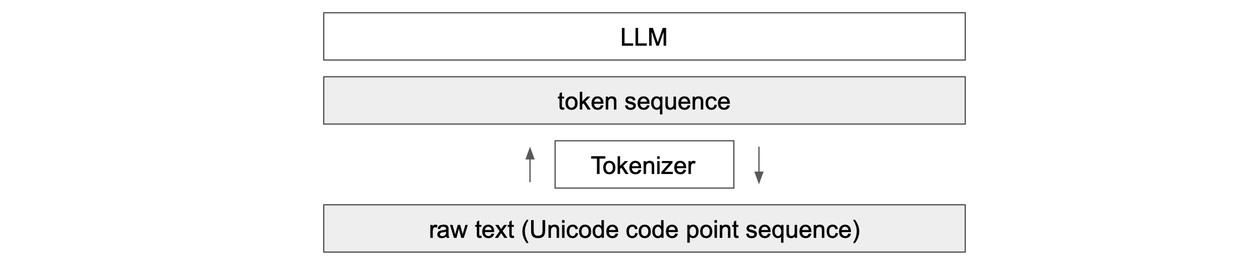



### Tokenizer modelden ayrı bir aşama

```
ham metin  ⇄  [ Tokenizer: BPE, kendi eğitim verisi ]  ⇄  token dizisi  ⇄  [ LLM ]
```

- Tokenizer'ın **kendi eğitim verisi** var, LLM'inkiyle aynı olmak zorunda değil. Tokenizer bir kez BPE ile eğitiliyor, sonra donduruluyor. LLM eğitimi boyunca hiç değişmiyor.
- LLM metni hiç görmüyor, yalnızca token id'lerini görüyor. "Model `ş` harfini biliyor mu?" sorusunun cevabı, `ş`'nin hangi token'ların içine gömüldüğüne bağlı.
- **Tokenizer'ın eğitim verisindeki dil karışımı önemli:** Bir dil o veride ne kadar çoksa o dil için o kadar çok birleştirme öğreniliyor ve o dilin metinleri o kadar kısa dizilere iniyor. Bağlam penceresi sınırlı olduğu için bu doğrudan LLM'in performansını etkiliyor. Görev 5'teki Türkçe/İngilizce farkının kökü burada.

# **3- encode ve decode yaz. decode(encode(metin)) metnin kendisini vermeli, Türkçe karakterli ve emoji içeren bir örnekle göster. Bazı token dizileri geçerli UTF-8 değil: decode bu durumda ne yapmalı, neden? (0:42:47 - 0:57:36)**

**decoding**

Given a sequence of integers in the range [0, vocab_size], what is the text?

In [22]:
vocab = {idx: bytes([idx]) for idx in range(256)}
for (p0, p1), idx in merges.items():
    vocab[idx] = vocab[p0] + vocab[p1]

def decode(ids):
  # given ids (list of integers), return Python string
  tokens = b"".join(vocab[idx] for idx in ids)
  text = tokens.decode("utf-8", errors="replace")
  return text

print(decode([128]))

�


### decode: token id'lerinden metne

**`vocab` tablosu:** Her token id'sinin hangi byte'lara karşılık geldiğini tutuyor.
- İlk 256 id tek byte: `vocab[97] = b'a'`.
- Sonraki her id, birleştirdiği iki token'ın byte'larının uç uca eklenmiş hali: `vocab[256] = vocab[101] + vocab[32] = b'e '`.
- Tablo `merges`'i **ekleme sırasıyla** gezerek kuruluyor. Bu sıra şart: `vocab[275] = vocab[259] + vocab[256]` satırı çalışırken 259 ve 256 tabloda olmalı. Python 3.7'den beri sözlükler ekleme sırasını koruyor, o yüzden düz bir `for` yetiyor.

**`decode`:** id'lerin byte'larını `b"".join` ile uç uca ekleyip sonucu UTF-8 olarak okuyor.

### Bazı token dizileri geçerli UTF-8 değil: decode ne yapmalı?

`decode([128])` hata vermesi gereken bir girdi: `128 = 10000000`, `10` ile başlıyor, yani bir **devam byte'ı**. Önünde başlangıç byte'ı olmadan anlamı yok. Varsayılan `.decode("utf-8")` burada `UnicodeDecodeError: invalid start byte` fırlatıyor. Kendi tokenizer'ımızda bunun gerçek bir örneği de var: **263 = `b'\xe2\x80'`**, yani `’ “ ” —` işaretlerinin yarısı. `decode([263])` da tek başına geçerli değil.

**decode hata fırlatmamalı, geçersiz byte'ların yerine `�` (U+FFFD, "replacement character") koymalı.** Biz bunu `errors="replace"` ile yapıyoruz. Sebebi:

- decode'a gelen dizi çoğu zaman **modelin ürettiği** dizi. Model her adımda vocab'daki herhangi bir token'ı seçebilir, ürettiği dizinin geçerli UTF-8 olacağının garantisi yok.
- Katı bir decode, model bir kere kötü bir dizi üretti diye tüm programı çökertir. `replace` metnin geri kalanını korur ve bozuk yeri görünür bırakır.
- OpenAI da aynısını yapıyor. ChatGPT'de bazen gördüğünüz `�` buradan geliyor.

**Token token ekrana basan sistemlerde:** Bir karakterin byte'ları birden fazla token'a dağılmışsa (aşağıda Türkçe tokenizer'da 🚕'nin 4 byte'ı 4 ayrı token'a dağılıyor), token'ları tek tek decode eden bir sistem ekranda bir an `�` gösteriyor. Bütün dizi birlikte decode edilince düzeliyor.

**encoding**

In [23]:
merges

{(101, 32): 256,
 (105, 110): 257,
 (115, 32): 258,
 (116, 104): 259,
 (101, 114): 260,
 (99, 111): 261,
 (116, 32): 262,
 (226, 128): 263,
 (44, 32): 264,
 (97, 110): 265,
 (111, 114): 266,
 (100, 32): 267,
 (97, 114): 268,
 (101, 110): 269,
 (257, 103): 270,
 (261, 100): 271,
 (121, 32): 272,
 (46, 32): 273,
 (97, 108): 274,
 (259, 256): 275}

Eğitimden çıkan `merges` sözlüğü: hangi ikili, hangi id'yle, **hangi sırada** birleştirildi. encode bu sırayı birebir tekrar edecek.

In [24]:
def encode(text):
  # given a string, return list of integers (the tokens)
  tokens = list(text.encode("utf-8"))
  while len(tokens) >= 2:
    stats = get_stats(tokens)
    pair = min(stats, key=lambda p: merges.get(p, float("inf")))
    if pair not in merges:
      break # nothing else can be merged
    idx = merges[pair]
    tokens = merge(tokens, pair, idx)
  return tokens

print(encode(""))

[]


### encode: metinden token id'lerine

1. Metni UTF-8 byte'larına çeviriyoruz.
2. Döngünün her turunda dizideki tüm ikilileri buluyoruz ve içlerinden **eğitimde en erken öğrenilmiş** olanı seçiyoruz: `min(stats, key=lambda p: merges.get(p, float("inf")))`. `merges.get(p)` o ikilinin id'si, yani kaçıncı sırada öğrenildiği. `merges`'te olmayan ikililer sonsuz alıyor.
3. Seçilen ikili `merges`'te yoksa, yani en küçük değer bile sonsuzsa, birleştirilecek bir şey kalmamıştır ve duruyoruz. Varsa birleştirip devam ediyoruz.

**Neden "en sık" değil de "en erken"?** encode'un eğitimde olanı birebir tekrar etmesi gerekiyor. Sonraki birleştirmeler öncekilerin ürettiği token'lar üzerine kurulu: `"the "` (275) ancak `"th"` (259) ve `"e "` (256) oluştuktan sonra oluşabilir. Yeni metinde sıklığa bakarsak sırayı bozarız ve aynı metin eğitimde öğrenilmemiş, tutarsız token'lara bölünür. Sıklık yalnızca eğitimde kullanılıyor, encode'da yalnızca sıra var.

**Kenar durum:** `while len(tokens) >= 2` koşulu boş metni ve tek karakteri koruyor. İkili yoksa `min` boş bir sözlükte hata verirdi. `encode("")` → `[]`.

In [25]:
print(decode(encode("hello world")))

hello world


In [26]:
text2 = decode(encode(text))
print(text2 == text)

True


**Gidiş-dönüş testi:** `decode(encode(text)) == text` → `True`. Bilgi kaybı yok, çünkü her token sonuçta byte'ların birleşimi ve hiçbir byte atılmıyor.

Tersi her zaman doğru değil: `encode(decode(ids)) == ids` garanti değil. Rastgele bir id dizisi geçerli bir metne karşılık gelmeyebilir (263 gibi). Gelse bile, örneğin `[116, 104]` (`t`, `h` ayrı ayrı), encode aynı metni `[259]` diye yazar.

In [27]:
valtext = "Many common characters, including numerals, punctuation, and other symbols, are unified within the standard and are not treated as specific to any given writing system. Unicode encodes thousands of emoji, with the continued development thereof conducted by the Consortium as a part of the standard.[4] Moreover, the widespread adoption of Unicode was in large part responsible for the initial popularization of emoji outside of Japan. Unicode is ultimately capable of encoding more than 1.1 million characters."
valtext2 = decode(encode(valtext))
print(valtext2 == valtext)

True


valtext tokenizer'ın eğitimde hiç görmediği bir metin. Bunda da `True` almamız, encode/decode'un sadece eğitim metnini ezberlemediğini, her metinde kayıpsız çalıştığını gösteriyor.

### Türkçe karakterli ve emojili örnek

encode ve decode fonksiyonları global `merges` ve `vocab`'ı kullanıyor. O yüzden Türkçe tokenizer'a geçmek için fonksiyonlara dokunmamıza gerek yok, sadece bu iki sözlüğü Türkçe olanlarla değiştiriyoruz. Bu aslında tokenizer'ın ne olduğunu da gösteriyor: tokenizer = merges sözlüğü.

In [28]:
en_merges, en_vocab = merges, vocab # İngilizce tokenizer'ı kenara koyuyoruz
merges, vocab = tr_merges, tr_vocab # artık encode ve decode Türkçe tokenizer'la çalışıyor

ornek = "Pijamalı hasta yağız şoföre çabucak güvendi 🚕"
ids_ornek = encode(ornek)
print(ids_ornek)
print("byte:", len(ornek.encode("utf-8")), "| token:", len(ids_ornek))
print([decode([i]) for i in ids_ornek]) # her token'ı tek tek decode ediyoruz
print(decode(ids_ornek))
print(decode(ids_ornek) == ornek)

[80, 105, 106, 300, 273, 274, 104, 306, 557, 121, 329, 429, 262, 786, 592, 263, 268, 333, 941, 372, 403, 118, 778, 240, 159, 154, 149]
byte: 55 | token: 27
['P', 'i', 'j', 'am', 'al', 'ı ', 'h', 'as', 'ta ', 'y', 'ağ', 'ız ', 'ş', 'of', 'ör', 'e ', 'ç', 'ab', 'uc', 'ak ', 'gü', 'v', 'endi ', '�', '�', '�', '�']
Pijamalı hasta yağız şoföre çabucak güvendi 🚕
True


In [29]:
# Türkçe metnin bir parçasında da gidiş dönüş testi. tüm metni encode etmek uzun sürüyor, ilk 20 bin karakter yeterli
parca = tr_text[:20000]
print(decode(encode(parca)) == parca)

True


Türkçe cümle 55 byte'tı, tokenizer'ımız bunu 27 token'a indirdi. Token'lara tek tek bakınca `'ı '`, `'ta '`, `'ız '`, `'ak '`, `'endi '` gibi kelime sonu + boşluk token'larını görüyoruz.

Emoji ilginç: 🚕 Ömer Seyfettin metninde hiç geçmediği için hiç birleşmemiş, 4 ayrı byte olarak kalmış (240, 159, 154, 149). Bu 4 token'ı tek tek decode edince 4 tane `�` çıkıyor çünkü her biri bir karakterin sadece bir parçası. Ama hepsini birlikte decode edince 🚕 geri geliyor ve `decode(encode(ornek)) == ornek` True. Türkçe metnin ilk 20 bin karakterinde de True.

Bu yüzden cevabı token token ekrana basan bir chatbot'ta bazen bir anlığına `�` görürüz: karakterin byte'ları birden fazla token'a dağılmış ve sistem onları tek tek decode etmiş. Token'lar birlikte decode edilince düzeliyor.

In [30]:
# tek başına geçerli utf-8 olmayan token'lar. 128 tek başına bir devam byte'ı
print(decode([128]))
print(en_vocab[263], "->", repr(en_vocab[263].decode("utf-8", errors="replace"))) # İngilizce tokenizer'daki yarım karakter

# Türkçe vocab'da da tek başına decode edilemeyen token'ları bulalım
yarim = []
for idx in range(256, tr_vocab_size):
    try:
        tr_vocab[idx].decode("utf-8") # errors="replace" olmadan, katı decode
    except UnicodeDecodeError:
        yarim.append(idx)
print(len(yarim), "tane yarım karakterli token var:")
for idx in yarim[:10]:
    print(idx, tr_vocab[idx], "->", repr(decode([idx])))

�
b'\xe2\x80' -> '�'
1 tane yarım karakterli token var:
295 b'\xe2\x80' -> '�'


In [31]:
# errors="replace" olmasaydı ne olurdu
try:
    tr_vocab[yarim[0]].decode("utf-8")
except UnicodeDecodeError as e:
    print("UnicodeDecodeError:", e)

UnicodeDecodeError: 'utf-8' codec can't decode bytes in position 0-1: unexpected end of data


Türkçe vocab'daki 768 yeni token'ın sadece 1 tanesi tek başına geçerli UTF-8 değil: 295 = `b'\xe2\x80'`. Bu İngilizce tokenizer'daki 263'ün aynısı: `—` işaretinin (`e2 80 94`) ilk iki byte'ı. Ömer Seyfettin'de diyaloglar hep `—` ile başladığı için bu ikili çok sık geçiyor. Türkçe harflerin hiçbiri yarım kalmamış, çünkü ı, ü, ş gibi harflerin iki byte'ı her zaman yan yana geliyor ve BPE onları en başta birleştiriyor. Yarım token'lar 3 byte'lık karakterlerde çıkıyor: `—`, `“`, `’` gibi işaretler aynı ilk iki byte'ı (`e2 80`) paylaşıyor ve BPE bu ortak kısmı birleştiriyor.

**decode bu durumda ne yapmalı:** `errors="replace"` olmadan decode yukarıdaki gibi `UnicodeDecodeError` fırlatıyor. Bizim decode'umuz hata fırlatmıyor, bozuk byte'ların yerine `�` (U+FFFD) koyuyor. Sebebi şu: decode'a gelen token dizisi çoğu zaman modelin ürettiği dizi oluyor ve model her adımda vocab'daki herhangi bir token'ı seçebilir. Ürettiği dizinin geçerli UTF-8 olacağının hiçbir garantisi yok. Model bir kere kötü bir dizi üretti diye bütün programın çökmesini istemeyiz. `replace` metnin geri kalanını koruyor ve bozuk yeri de görünür bırakıyor. OpenAI da aynısını yapıyor.

# **4- GPT-4'ün regex desenini ekle. Metni önce GPT-4'ün deseniyle parçalara böl, BPE'yi her parçada ayrı çalıştır. Tokenizer'ı yeniden eğit, birleştirmeleri öncekiyle karşılaştır. Sonra "Ankara'dan" ve "İstanbul'da" gibi kesme işaretli kelimeleri bu desenle böl. Desen İngilizce için yazılmış: Türkçede ne yapıyor, kendi cümlelerinle yaz. (0:57:36 - 1:11:38)**

### Forced splits using regex patterns (GPT series)


**Sorun:** Düz BPE metnin tamamına bakıyor ve kategori gözetmeden birleştiriyor. GPT-2 makalesinin 2.2. bölümündeki örnek: `dog.`, `dog!`, `dog?` için ayrı ayrı token'lar öğreniliyor ve vocab'ın bir kısmı aynı kelimenin noktalama varyasyonlarına harcanıyor.

**Çözüm:** Metni önce bir regex ile **parçalara** bölmek. BPE her parçanın içinde ayrı çalışıyor ve hiçbir birleştirme parça sınırını geçemiyor. Harf, sayı, noktalama ve boşluk birbirine hiç yapışamıyor. encode'da da metin önce parçalanıyor, her parça ayrı token'lanıyor, sonuçlar art arda ekleniyor.

In [32]:
import regex as re
gpt2pat = re.compile(r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+""")

print(re.findall(gpt2pat, "Hello've world123 how's are you!!!?"))

['Hello', "'ve", ' world', '123', ' how', "'s", ' are', ' you', '!!!?']


Çıktı:
`['Hello', "'ve", ' world', '123', ' how', "'s", ' are', ' you', '!!!?']`

**GPT-2 deseni, parça parça** (`|` "ya da" demek, soldan sağa ilk eşleşen kazanıyor):

| Parça | Ne yakalıyor | Örnek |
|---|---|---|
| `'s\|'t\|'re\|'ve\|'m\|'ll\|'d` | İngilizce kısaltmalar | `'ve`, `'s` |
| ` ?\p{L}+` | önünde en fazla bir boşluk olan harf dizisi | `' world'` |
| ` ?\p{N}+` | önünde en fazla bir boşluk olan sayı dizisi | `'123'` |
| ` ?[^\s\p{L}\p{N}]+` | harf, sayı ya da boşluk olmayan her şey (noktalama) | `'!!!?'` |
| `\s+(?!\S)` | boşluklar, **sondaki biri hariç** | |
| `\s+` | kalan boşluklar | |

- `\p{L}` herhangi bir dildeki harf, `\p{N}` herhangi bir sayı. Python'un standart `re` modülü bunları tanımıyor, o yüzden `regex` paketi kullanılıyor (`import regex as re`).
- Boşluk kelimenin **başına** yapışıyor: `' world'`. Bu yüzden `"world"` ve `" world"` farklı token'lar.
- `world123` → `' world'` + `'123'`: harf ile sayı ayrıldı.

**Karpathy'nin eleştirileri:**
- Kısaltma kuralı büyük/küçük harfe duyarlı: `HOW'S`'teki `'S` yakalanmıyor, `'` ve `S` ayrı düşüyor.
- Tipografik kesme `’` (U+2019) kuralda yok.
- Kural tamamen İngilizceye göre yazılmış. Görev 4'te bunun Türkçede ne yaptığına bakıyoruz.
- OpenAI tokenizer'ı **eğiten** kodu hiç yayınlamadı, yalnızca desen ve hazır merge'ler var.

In [33]:
example = """
for i in range(1, 101):
    if i % 3 == 0 and i % 5 == 0:
        print("FizzBuzz")
    elif i % 3 == 0:
        print("Fizz")
    elif i % 5 == 0:
        print("Buzz")
    else:
        print(i)
"""
print(re.findall(gpt2pat, example))

['\n', 'for', ' i', ' in', ' range', '(', '1', ',', ' 101', '):', '\n   ', ' if', ' i', ' %', ' 3', ' ==', ' 0', ' and', ' i', ' %', ' 5', ' ==', ' 0', ':', '\n       ', ' print', '("', 'FizzBuzz', '")', '\n   ', ' elif', ' i', ' %', ' 3', ' ==', ' 0', ':', '\n       ', ' print', '("', 'Fizz', '")', '\n   ', ' elif', ' i', ' %', ' 5', ' ==', ' 0', ':', '\n       ', ' print', '("', 'Buzz', '")', '\n   ', ' else', ':', '\n       ', ' print', '(', 'i', ')', '\n']


Çıktının başı: `['\n', 'for', ' i', ' in', ' range', '(', '1', ',', ' 101', '):', '\n   ', ' if', ...]`

`\s+(?!\S)` burada görünüyor: girintideki 4 boşluk `'\n   '` (satır sonu + 3 boşluk) ve `' if'` diye bölündü. Son boşluk kelimeye bırakıldı, böylece `" if"` her yerde aynı token oluyor. Yine de GPT-2'de girinti boşlukları ayrı ayrı token'lanıyordu ve bu Python kodunu çok uzatıyordu. GPT-4 bunu düzeltti.

### GPT-4'ün deseni

GPT-2'nin deseni çalışıyor ama yukarıda saydığımız sorunları var. GPT-4'te OpenAI deseni değiştirdi. Bu desen `tiktoken`'ın içinde `cl100k_base` için tanımlı, Karpathy'nin minbpe reposunda da `GPT4_SPLIT_PATTERN` diye geçiyor.

GPT-2'den farkları:
- kısaltmalar artık büyük/küçük harfe duyarsız: `(?i:...)`
- harf dizisinin önüne boşluk dışında bir karakter de gelebiliyor: `[^\r\n\p{L}\p{N}]?`
- sayılar en fazla 3 haneli parçalara bölünüyor: `\p{N}{1,3}`
- satır sonları ayrı ele alınıyor

In [34]:
GPT4_SPLIT_PATTERN = r"""'(?i:[sdmt]|ll|ve|re)|[^\r\n\p{L}\p{N}]?+\p{L}+|\p{N}{1,3}| ?[^\s\p{L}\p{N}]++[\r\n]*|\s*[\r\n]|\s+(?!\S)|\s+"""
gpt4pat = re.compile(GPT4_SPLIT_PATTERN)

print(re.findall(gpt4pat, "Hello've world123 how's are you!!!?"))
# farkı görmek için büyük harfli kısaltma ve uzun sayı
print("GPT-2:", re.findall(gpt2pat, "HOW'S 1234567"))
print("GPT-4:", re.findall(gpt4pat, "HOW'S 1234567"))

['Hello', "'ve", ' world', '123', ' how', "'s", ' are', ' you', '!!!?']
GPT-2: ['HOW', "'", 'S', ' 1234567']
GPT-4: ['HOW', "'S", ' ', '123', '456', '7']


Şimdi Türkçe metni bu desenle parçalara bölüyoruz. BPE'yi metnin tamamında değil her parçanın içinde ayrı çalıştıracağız. Böylece hiçbir birleştirme iki parçanın sınırını geçemeyecek.

In [35]:
tr_chunks = re.findall(gpt4pat, tr_text)
print(len(tr_chunks), "parça")
print(tr_chunks[:30])

149252 parça
['Pembe', ' İncili', ' Kaftan', '\n\n', 'Büyük', ' kubbeli', ' serin', ' Dîvan', ',', ' bugün', ' daha', ' sakin', ',', ' daha', ' gölgeliydi', '.', ' Pencerelerden', ' süzülen', ' mavi', ',', ' mor', ',', ' sincâbî', ' bahar', ' ışıkları', ',', ' çinilerinin', ' yeşil', ' derinliklerinde', ' birikiyor']


In [36]:
def train_regex(text_chunks, vocab_size):
    ids = [list(ch.encode("utf-8")) for ch in text_chunks] # her parça ayrı bir byte listesi
    merges = {}
    for i in range(vocab_size - 256):
        stats = {}
        for chunk_ids in ids: # sayımları tüm parçalardan tek bir sözlükte topluyoruz
            for pair in zip(chunk_ids, chunk_ids[1:]): # parçanın içindeki ikililer. parçalar arası ikili hiç sayılmıyor
                stats[pair] = stats.get(pair, 0) + 1
        pair = max(stats, key=stats.get)
        idx = 256 + i
        ids = [merge(chunk_ids, pair, idx) for chunk_ids in ids] # merge'ü her parçaya ayrı uyguluyoruz
        merges[pair] = idx
    return merges, ids

rx_merges, rx_ids = train_regex(tr_chunks, tr_vocab_size) # aynı vocab boyutu: 1024

rx_vocab = {idx: bytes([idx]) for idx in range(256)}
for (p0, p1), idx in rx_merges.items():
    rx_vocab[idx] = rx_vocab[p0] + rx_vocab[p1]

In [37]:
# ilk 20 birleştirmeyi yan yana koyalım
print(f"{'id':>4}  {'regex yok':12} {'GPT-4 regex':12}")
for idx in range(256, 276):
    print(f"{idx:>4}  {goster(idx, tr_vocab):12} {goster(idx, rx_vocab):12}")

  id  regex yok    GPT-4 regex 
 256  'ı'          'ı'         
 257  'n '         'ü'         
 258  'ü'          'ar'        
 259  'ar'         ' b'        
 260  '. '         'ş'         
 261  ', '         'er'        
 262  'ş'          'in'        
 263  'e '         'an'        
 264  'er'         ' k'        
 265  'a '         'en'        
 266  'i '         'ın'        
 267  'ir'         'ir'        
 268  'ç'          'ç'         
 269  'in'         ' d'        
 270  'ğ'          ' g'        
 271  'an'         'ğ'         
 272  'ak'         ' s'        
 273  'al'         'ak'        
 274  'ı '         'al'        
 275  'ın'         'di'        


In [38]:
# kelime sınırını geçen token'lar: içinde boşluk olmayan bir karakterden sonra boşluk gelen token'lar ("e " gibi)
for ad, v in [("regex yok", tr_vocab), ("GPT-4 regex", rx_vocab)]:
    s = [v[i].decode("utf-8", errors="replace") for i in range(256, tr_vocab_size)]
    gecen = [t for t in s if re.search(r"\S\s", t)]
    print(f"{ad:12} {len(gecen):3} token kelime sınırını geçiyor. örnek: {gecen[:8]}")

rx_len = sum(len(c) for c in rx_ids)
print(f"sıkıştırma oranı, regex yok:   {len(tr_tokens) / len(tr_ids):.2f}X")
print(f"sıkıştırma oranı, GPT-4 regex: {len(tr_tokens) / rx_len:.2f}X")

regex yok    270 token kelime sınırını geçiyor. örnek: ['n ', '. ', ', ', 'e ', 'a ', 'i ', 'ı ', 'bir ']
GPT-4 regex    8 token kelime sınırını geçiyor. örnek: ['.\n', ':\n', '?\n', '.\n\n', '...\n', '!\n', '..\n', '...\n\n']
sıkıştırma oranı, regex yok:   2.71X
sıkıştırma oranı, GPT-4 regex: 2.70X


**Regex'li ve regex'siz tokenizer'ın karşılaştırması:**

İlk 20'de `ı`, `ü`, `ş`, `ç`, `ğ`, `ar`, `er`, `in`, `an`, `ir`, `ak`, `al` ikisinde de var, yani harf toplama ve ekler aynı. Fark kelime sonu + boşluk token'larında. Regex'siz tokenizer'da `'n '`, `'. '`, `', '`, `'e '`, `'a '`, `'i '`, `'ı '` vardı, regex'li tokenizer'da hiçbiri yok. Onların yerine `' b'`, `' k'`, `' d'`, `' g'`, `' s'` gibi boşlukla başlayan kelime başları geldi, çünkü desen boşluğu kelimenin önüne yapıştırıyor. `"n "` artık bir token olamaz çünkü n bir parçanın sonunda, boşluk ise bir sonraki parçanın başında.

Bütün vocab'a bakınca fark daha net görünüyor: regex'siz tokenizer'da **270 token** kelime sınırını geçiyor (`'bir '`, `'a başladı'`, `'bir şey'` gibi). Regex'li tokenizer'da sadece **8 token**, onların hepsi de noktalama + satır sonu (`'.\n'` gibi). Bu da desenin bilerek izin verdiği bir şey (`[^\s\p{L}\p{N}]++[\r\n]*` kısmı).

Sıkıştırma oranı neredeyse hiç değişmedi: **2,71X → 2,70X**. Yani regex sıkıştırmadan neredeyse hiçbir şey kaybettirmedi, ama vocab'ı kelime sınırlarına uyan parçalara harcattı. Aynı vocab boyutunda daha "temiz" token'lar elde ettik.

Regex'li tokenizer'ın encode'u da aynı mantıkla çalışıyor: metni desenle parçala, her parçayı ayrı encode et, sonuçları uç uca ekle. Parçanın içindeki encode bizim encode fonksiyonumuzun aynısı.

In [39]:
def encode_regex(text, merges):
    ids = []
    for chunk in re.findall(gpt4pat, text): # önce parçalara bölüyoruz
        chunk_ids = list(chunk.encode("utf-8"))
        while len(chunk_ids) >= 2: # sonra her parçada bildiğimiz encode
            stats = get_stats(chunk_ids)
            pair = min(stats, key=lambda p: merges.get(p, float("inf")))
            if pair not in merges:
                break
            chunk_ids = merge(chunk_ids, pair, merges[pair])
        ids.extend(chunk_ids)
    return ids

cumle2 = "Ankara'dan geldim, 2026'da İstanbul'a taşındım!"
ids2 = encode_regex(cumle2, rx_merges)
print([rx_vocab[i].decode("utf-8", errors="replace") for i in ids2])
print(b"".join(rx_vocab[i] for i in ids2).decode("utf-8") == cumle2) # gidiş dönüş burada da tutuyor

['A', 'n', 'k', 'ar', 'a', "'d", 'an', ' geldi', 'm', ',', ' ', '2', '0', '2', '6', "'d", 'a', ' İstanbul', "'a", ' taş', 'ın', 'dım', '!']
True


### Kesme işaretli kelimeler

In [40]:
kelimeler = ["Ankara'dan", "İstanbul'da", "İzmir'de", "İzmir'e", "Türkiye'nin", "Paris'te",
             "Ankara'sı", "Ahmet'miş", "ANKARA'DAN", "2026'da", "Ankara’dan"]
for k in kelimeler:
    print(f"{k:12} GPT-2: {str(re.findall(gpt2pat, k)):32} GPT-4: {re.findall(gpt4pat, k)}")

Ankara'dan   GPT-2: ['Ankara', "'d", 'an']           GPT-4: ['Ankara', "'d", 'an']
İstanbul'da  GPT-2: ['İstanbul', "'d", 'a']          GPT-4: ['İstanbul', "'d", 'a']
İzmir'de     GPT-2: ['İzmir', "'d", 'e']             GPT-4: ['İzmir', "'d", 'e']
İzmir'e      GPT-2: ['İzmir', "'", 'e']              GPT-4: ['İzmir', "'e"]
Türkiye'nin  GPT-2: ['Türkiye', "'", 'nin']          GPT-4: ['Türkiye', "'nin"]
Paris'te     GPT-2: ['Paris', "'t", 'e']             GPT-4: ['Paris', "'t", 'e']
Ankara'sı    GPT-2: ['Ankara', "'s", 'ı']            GPT-4: ['Ankara', "'s", 'ı']
Ahmet'miş    GPT-2: ['Ahmet', "'m", 'iş']            GPT-4: ['Ahmet', "'m", 'iş']
ANKARA'DAN   GPT-2: ['ANKARA', "'", 'DAN']           GPT-4: ['ANKARA', "'D", 'AN']
2026'da      GPT-2: ['2026', "'d", 'a']              GPT-4: ['202', '6', "'d", 'a']
Ankara’dan   GPT-2: ['Ankara', '’', 'dan']           GPT-4: ['Ankara', '’dan']


In [41]:
# Ömer Seyfettin metninde kesme işaretiyle başlayan en sık parçalar
from collections import Counter
kesmeli = Counter(c for c in tr_chunks if c.startswith("'"))
print(kesmeli.most_common(20))

[("'d", 252), ("'in", 146), ("'a", 129), ("'ın", 121), ("'nın", 89), ("'nin", 87), ("'e", 75), ("'ya", 74), ("'ye", 58), ("'un", 58), ("'t", 51), ("'i", 49), ("'yi", 49), ("'ı", 45), ("'la", 29), ("'u", 27), ("'yı", 26), ("'ün", 20), ("'le", 19), ("'nun", 18)]


Kendi metnimizde de durum aynı. Kesme işaretinden sonra gelen en sık parça `'d` (252 kere), yani -da, -de, -dan, -den ekleri hep `'d` + geri kalanı diye bölünmüş. Aynı şey `'t` için de geçerli (51 kere, -ta/-te ekleri). Bizim tokenizer'ımız `'dan` ya da `'de` diye bir token hiç öğrenemez, en fazla `'d` ve `an` öğrenebilir. Yukarıdaki `Ankara'dan geldim` örneğinde de tam olarak bu oldu. Buna karşılık `'in`, `'nın`, `'ya`, `'ye` gibi ekler bütün kalıyor.

GPT-2'nin deseninde durum daha da kötü: kısaltma kuralı büyük/küçük harfe duyarlı olduğu ve harf dizisinin önüne sadece boşluk gelebildiği için `İzmir'e` bile `İzmir` · `'` · `e` diye üçe bölünüyor.

### Desen Türkçede ne yapıyor?

**İyi tarafı:** `\p{L}` "herhangi bir dildeki harf" demek. `ç ğ ı ö ş ü İ` de harf sayılıyor ve Türkçe kelimeler harflerinden bölünmüyor: `' taşındım'` tek parça. Desen ASCII'ye göre yazılsaydı (`[a-zA-Z]`) her Türkçe harfte kelime ortadan kesilirdi.

**Sorun kısaltma kuralında:** `'(?i:[sdmt]|ll|ve|re)` İngilizce için yazılmış. `'d`, `'s`, `'m`, `'t` İngilizcede birer kelimenin kısaltması: *I'd, it's, I'm, don't*. Türkçede kesme işareti özel ismi ekinden ayırıyor ve desen, `d`, `s`, `m` ya da `t` ile başlayan Türkçe ekleri İngilizce kısaltma sanıp **ilk harflerinden koparıyor**:

- `Ankara'dan` → `Ankara` · `'d` · `an` (ayrılma eki `-dan` ikiye bölündü)
- `İstanbul'da` → `İstanbul` · `'d` · `a`
- `Paris'te` → `Paris` · `'t` · `e`

Başka harfle başlayan ekler bütün kalıyor: `İzmir'e` → `İzmir` · `'e`, `Türkiye'nin` → `Türkiye` · `'nin`.

**Sonuçları:**

1. **Aynı türden ekler tutarsız bölünüyor.** Hangi parçalara ayrılacağına ekin dilbilgisel görevi değil ilk harfi karar veriyor: `İzmir'e` tek parça, `İzmir'de` üç parça.
2. **Model `'dan` ekini hiç tek parça olarak göremiyor.** BPE parça sınırını geçemediği için `'d` ile `an` hiçbir zaman birleşemiyor. Vocab'ı büyütmek bunu düzeltmez, çünkü regex BPE'den **önce** çalışıyor.
3. **Vocab'ın bir kısmı Türkçede anlamı olmayan `'d`, `'s`, `'m`, `'t` parçalarına gidiyor.** `(?i:...)` yüzünden büyük harfle de aynısı oluyor: `ANKARA'DAN` → `'D` · `AN`.
4. **Metin temizliği tokenization'ı değiştiriyor.** Tipografik kesme `’` kısaltma kuralına takılmıyor: `Ankara’dan` → `Ankara` · `’dan`. Aynı kelime kesme işaretinin türüne göre farklı bölünüyor. Geçen haftaki "temizlik vocab'ı belirliyor" dersinin tokenizer'daki karşılığı bu.
5. **Sayılar:** 3 haneden bölündüğü için `2026'da` → `202` · `6` · `'d` · `a`, dört parça.

Kesme işareti olmayan eklerde (`ev·ler·imiz·den`) desen kelimeyi hiç bölmüyor, ekleri bulmak tamamen BPE'ye kalıyor. Kısacası desen Türkçe morfolojisine yardım etmiyor, kesme işaretli özel isimlerde de onu bozuyor.

# **5- Türkçe ile İngilizceyi karşılaştır. Aynı paragrafın Türkçesini ve İngilizcesini al. GPT-4'ün tokenizer'ıyla (tiktoken, "cl100k_base") ikisini de token'la, kelime başına kaç token düştüğünü yaz. Sonra aynı Türkçe paragrafı kendi tokenizer'ınla token'la. Türkçenin eklemeli yapısı bu sayıları nasıl etkiliyor?**

In [42]:
import tiktoken # Colab'da yoksa: !pip install tiktoken
enc = tiktoken.get_encoding("cl100k_base") # GPT-4'ün tokenizer'ı

tr_par = ("Sabah erkenden kalktım ve pencereyi açtım. Dışarıda hafif bir yağmur yağıyordu, sokaklar henüz sessizdi. "
          "Kahvaltıdan sonra kitaplarımı alıp kütüphaneye gittim. Akşama kadar orada çalıştım, sonra arkadaşlarımla buluşup eve döndük.")
en_par = ("I got up early in the morning and opened the window. A light rain was falling outside, and the streets were still quiet. "
          "After breakfast, I took my books and went to the library. I studied there until evening, then met my friends and we went home.")

def say(ad, ids, metin):
    kelime = len(metin.split())
    print(f"{ad:34} kelime: {kelime:3}  token: {len(ids):3}  token/kelime: {len(ids) / kelime:.2f}  byte/token: {len(metin.encode('utf-8')) / len(ids):.2f}")

say("İngilizce, cl100k_base", enc.encode(en_par), en_par)
say("Türkçe, cl100k_base", enc.encode(tr_par), tr_par)
say("Türkçe, benim BPE (regex yok)", encode(tr_par), tr_par)          # global merges şu an Türkçe tokenizer
say("Türkçe, benim BPE (GPT-4 regex)", encode_regex(tr_par, rx_merges), tr_par)
print(f"aynı içerik, cl100k ile Türkçe / İngilizce token oranı: {len(enc.encode(tr_par)) / len(enc.encode(en_par)):.2f}")

İngilizce, cl100k_base             kelime:  47  token:  54  token/kelime: 1.15  byte/token: 4.57
Türkçe, cl100k_base                kelime:  29  token:  91  token/kelime: 3.14  byte/token: 2.80
Türkçe, benim BPE (regex yok)      kelime:  29  token:  95  token/kelime: 3.28  byte/token: 2.68
Türkçe, benim BPE (GPT-4 regex)    kelime:  29  token:  92  token/kelime: 3.17  byte/token: 2.77
aynı içerik, cl100k ile Türkçe / İngilizce token oranı: 1.69


In [43]:
# kelimeler hangi parçalara bölünüyor
for k in [" evlerimizden", " kütüphaneye", " arkadaşlarımla", " yağıyordu", " geliyorum", " houses", " library", " friends"]:
    gpt4 = [enc.decode_single_token_bytes(t).decode("utf-8", errors="replace") for t in enc.encode(k)]
    biz = [rx_vocab[i].decode("utf-8", errors="replace") for i in encode_regex(k, rx_merges)]
    print(f"{k:16} cl100k: {str(gpt4):46} bizim: {biz}")

 evlerimizden    cl100k: [' ev', 'ler', 'im', 'iz', 'den']              bizim: [' ev', 'ler', 'imiz', 'den']
 kütüphaneye     cl100k: [' k', 'üt', 'ü', 'phan', 'eye']               bizim: [' k', 'üt', 'üp', 'han', 'eye']
 arkadaşlarımla  cl100k: [' ark', 'ada', 'ş', 'ları', 'ml', 'a']        bizim: [' ark', 'ad', 'aş', 'lar', 'ım', 'la']
 yağıyordu       cl100k: [' ya', 'ğı', 'y', 'ord', 'u']                 bizim: [' y', 'ağ', 'ıyordu']
 geliyorum       cl100k: [' g', 'eli', 'y', 'orum']                     bizim: [' gel', 'iyor', 'um']
 houses          cl100k: [' houses']                                    bizim: [' h', 'o', 'us', 'es']
 library         cl100k: [' library']                                   bizim: [' ', 'li', 'b', 'rar', 'y']
 friends         cl100k: [' friends']                                   bizim: [' f', 'r', 'i', 'en', 'd', 's']


### Türkçe ve İngilizce karşılaştırması

| | Kelime | Token | Token / kelime | Byte / token |
|---|---|---|---|---|
| İngilizce, cl100k_base | 47 | 54 | 1,15 | 4,57 |
| Türkçe, cl100k_base | 29 | 91 | 3,14 | 2,80 |
| Türkçe, benim BPE (regex yok, vocab 1024) | 29 | 95 | 3,28 | 2,68 |
| Türkçe, benim BPE (GPT-4 regex, vocab 1024) | 29 | 92 | 3,17 | 2,77 |

GPT-4'ün tokenizer'ında Türkçede kelime başına 3,14 token düşüyor, İngilizcede 1,15. Yani neredeyse 3 kat. Ama burada bir şeye dikkat etmek lazım: Türkçe paragraf 29 kelime, İngilizcesi 47 kelime. Aynı şeyi anlatıyorlar ama Türkçe daha az kelimeyle anlatıyor, çünkü Türkçe eklemeli bir dil. `arkadaşlarımla` tek kelime, İngilizcede `with my friends` üç kelime. O yüzden kelime başına token iki dili kıyaslamak için adil bir ölçü değil. Asıl kıyaslanması gereken aynı içeriğin toplam token sayısı: Türkçe 91, İngilizce 54. **Aynı içerik Türkçede 1,69 kat daha fazla token tutuyor.**

**Bunun sebepleri:**

1. **Eklemeli yapı.** Bir Türkçe kelime kök + birçok ekten oluşuyor ve tokenizer bu ekleri ayrı token'lara bölüyor. `evlerimizden` = ev + ler + imiz + den.
2. **Tokenizer'ın eğitim verisi.** cl100k ağırlıklı olarak İngilizce ve kod üzerinde eğitildi. `houses`, `library`, `friends` tek token. Türkçe kelimeler ise anlamsız parçalara bölünüyor: `geliyorum` → `' g'` · `'eli'` · `'y'` · `'orum'`.
3. **UTF-8.** Her Türkçe harf 2 byte, bu da byte/token oranını aşağı çekiyor (İngilizcede 4,57, Türkçede 2,80).

**Kendi tokenizer'ımız:** Bizim vocab'ımız 1024, GPT-4'ünkü yaklaşık 100 bin, yani 100 kat küçük. Buna rağmen Türkçe paragrafta neredeyse aynı sayıda token çıkardı: cl100k 91, bizimki 92. Çünkü bizim 768 birleştirmemizin hepsi Türkçe parçalar, cl100k'nın 100 bin token'ının ise çok küçük bir kısmı Türkçeye ayrılmış. Bölünmelere bakınca da fark görülüyor. Bizim tokenizer'ımız Türkçe kelimeleri çoğu zaman eklerinden bölüyor:

- `geliyorum` → `' gel'` · `'iyor'` · `'um'` (kök + şimdiki zaman eki + şahıs eki)
- `evlerimizden` → `' ev'` · `'ler'` · `'imiz'` · `'den'`
- `yağıyordu` → `' y'` · `'ağ'` · `'ıyordu'`

İngilizce kelimelerde ise bizimki çok kötü: `houses` → `' h'` · `'o'` · `'us'` · `'es'`, çünkü hiç İngilizce görmedi. `kütüphaneye` ise ikisinde de kötü bölünüyor, çünkü Ömer Seyfettin metninde bu kelime neredeyse hiç geçmiyor.

**Sonuç:** Tokenizer hangi dilde eğitildiyse o dilde verimli oluyor. Türkçe bir model kullanırken İngilizce ağırlıklı bir tokenizer kullanırsak aynı bağlam penceresine 1,7 kat daha az metin sığar, model aynı içerik için daha fazla adım atar, API ücretleri token başına olduğu için de aynı metin daha pahalıya gelir.

## Özet

- Bir metin, bilgisayarda UTF-8 byte'larının dizisi. İngilizce harfler 1 byte, Türkçe harfler 2, emoji 4.
- Kod noktalarını vocab yapmak vocab'ı şişiriyor ve sabit değil. Ham byte'lar sabit ama diziyi uzatıyor. BPE ikisinin arasında: byte'larla başla, sık ikilileri birleştir.
- Tokenizer = `merges` sözlüğü. encode bu birleştirmeleri eğitimdeki sırayla uyguluyor, decode byte'ları birleştirip UTF-8 okuyor ve geçersiz byte'ların yerine `�` koyuyor.
- Regex ile ön bölme, birleştirmelerin harf / sayı / noktalama sınırını geçmesini engelliyor. Ama GPT-4'ün deseni İngilizceye göre yazılmış: Türkçe kesme işaretli ekleri tutarsız bölüyor.
- Tokenizer LLM'den ayrı eğitiliyor. Eğitim verisindeki dil oranı, o dilin metinlerinin ne kadar kısa dizilere ineceğini belirliyor. Türkçe bu yüzden İngilizceden daha fazla token tutuyor.